# 📑 **PENGARUH ADAPTIVE FEATURE SELECTION TERHADAP KINERJA MODEL RIME-XGBOOST DALAM PREDIKSI SUHU PERMANENT MAGNET SYNCHRONOUS MOTOR (PMSM)**
---

# **01. DATA PREPARATION**

In [ ]:
import os
import time
import warnings
import openpyxl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr, wilcoxon
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
print("✅ Seluruh Library Berhasil Dimuat!")

✅ Seluruh Library Berhasil Dimuat!


In [ ]:
# Download latest version
path = kagglehub.dataset_download("wkirgsn/electric-motor-temperature")

print("Path to dataset files:", path)

# Menampilkan daftar file hasil download
files = os.listdir(path)
print("Daftar file di dalam folder dataset:", files)

# Cara memuat file utama menggunakan path absolut hasil download
csv_path = os.path.join(path, 'measures_v2.csv')
print(f"\nMemuat data dari: {csv_path}")

df_downloaded = pd.read_csv(csv_path)
display(df_downloaded.head())

100%|██████████| 117M/117M [00:00<00:00, 125MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/wkirgsn/electric-motor-temperature/versions/3
Daftar file di dalam folder dataset: ['measures_v2.csv']

Memuat data dari: /root/.cache/kagglehub/datasets/wkirgsn/electric-motor-temperature/versions/3/measures_v2.csv


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
0,-0.450682,18.805172,19.086670,-0.350055,18.293219,0.002866,0.004419,0.000328,24.554214,18.316547,19.850691,0.187101,17
1,-0.325737,18.818571,19.092390,-0.305803,18.294807,0.000257,0.000606,-0.000785,24.538078,18.314955,19.850672,0.245417,17
2,-0.440864,18.828770,19.089380,-0.372503,18.294094,0.002355,0.001290,0.000386,24.544693,18.326307,19.850657,0.176615,17
3,-0.327026,18.835567,19.083031,-0.316199,18.292542,0.006105,0.000026,0.002046,24.554018,18.330833,19.850647,0.238303,17
4,-0.471150,18.857033,19.082525,-0.332272,18.291428,0.003133,-0.064317,0.037184,24.565397,18.326662,19.850639,0.208197,17


In [ ]:
df = pd.read_csv(csv_path)

TARGET = "pm"
FEATURES = ['u_q', 'coolant', 'stator_winding', 'u_d', 'stator_tooth', 'motor_speed', 'i_d', 'i_q', 'stator_yoke', 'ambient', 'torque']

=== TABEL STATISTIK DESKRIPTIF DATASET MENTAH ===
                    count     mean      std     min   median      max  \
u_q             1330816.0    54.28    44.17  -25.29    48.94   133.04   
coolant         1330816.0    36.23    21.79   10.62    26.90   101.60   
stator_winding  1330816.0    66.34    28.67   18.59    65.11   141.36   
u_d             1330816.0   -25.13    63.09 -131.53    -7.43   131.47   
stator_tooth    1330816.0    56.88    22.95   18.13    56.04   111.95   
motor_speed     1330816.0  2202.08  1859.66 -275.55  1999.98  6000.02   
i_d             1330816.0   -68.72    64.93 -278.00   -51.09     0.05   
i_q             1330816.0    37.41    92.18 -293.43    15.77   301.71   
pm              1330816.0    58.51    19.00   20.86    60.27   113.61   
stator_yoke     1330816.0    48.19    19.99   18.08    45.63   101.15   
ambient         1330816.0    24.57     1.93    8.78    24.80    30.71   
torque          1330816.0    31.11    77.14 -246.47    10.86   261.01   
p

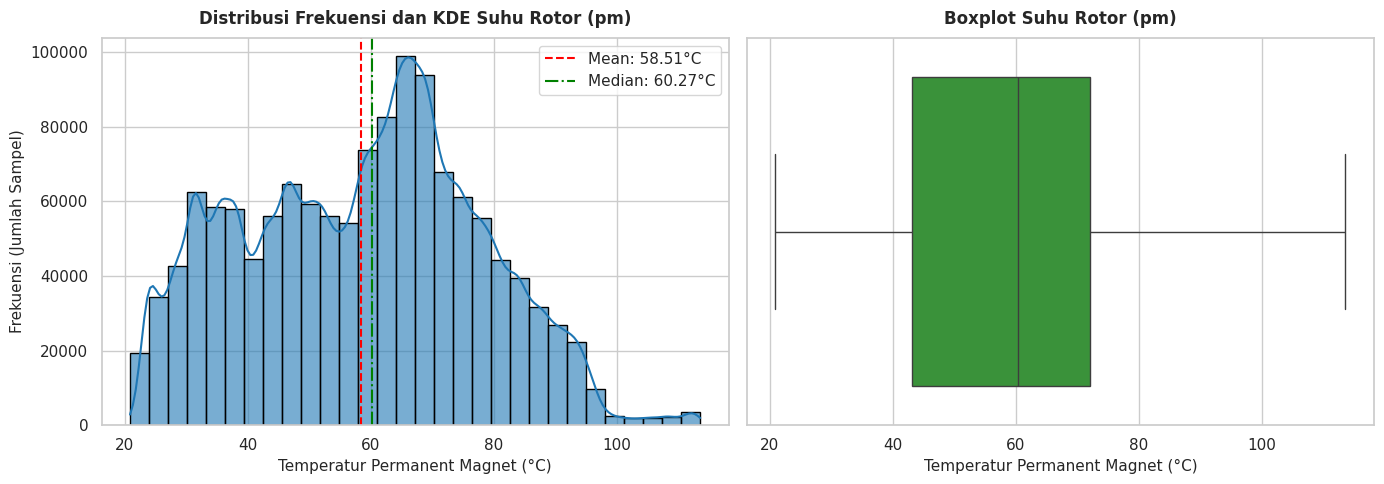

In [ ]:
# =========================================================================
# A. STATISTIK DESKRIPTIF DATASET
# =========================================================================
# Menghitung ringkasan statistik deskriptif
stat_deskriptif = df.describe().T[
    ["count", "mean", "std", "min", "50%", "max"]
]
stat_deskriptif.rename(columns={"50%": "median"}, inplace=True)

# Menambahkan perhitungan Skewness (Kepencengan) dan Kurtosis (Keruncingan)
stat_deskriptif["skewness"] = df.skew()
stat_deskriptif["kurtosis"] = df.kurt()

print("=== TABEL STATISTIK DESKRIPTIF DATASET MENTAH ===")
print(stat_deskriptif.round(2))

# =========================================================================
# B. VISUALISASI DISTRIBUSI TEMPERATUR PERMANENT MAGNET (pm)
# =========================================================================
# Set style grafik
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Plot Histogram + KDE (Kernel Density Estimation)
sns.histplot(
    data=df,
    x="pm",
    kde=True,
    color="#1f77b4",
    bins=30,
    ax=axes[0],
    edgecolor="black",
    alpha=0.6,
)
axes[0].set_title(
    "Distribusi Frekuensi dan KDE Suhu Rotor (pm)",
    fontsize=12,
    pad=10,
    fontweight="bold",
)
axes[0].set_xlabel("Temperatur Permanent Magnet (°C)", fontsize=11)
axes[0].set_ylabel("Frekuensi (Jumlah Sampel)", fontsize=11)

# Menambahkan garis indikator Mean dan Median pada Histogram
mean_pm = df["pm"].mean()
median_pm = df["pm"].median()
axes[0].axvline(
    mean_pm,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {mean_pm:.2f}°C",
)
axes[0].axvline(
    median_pm,
    color="green",
    linestyle="-.",
    linewidth=1.5,
    label=f"Median: {median_pm:.2f}°C",
)
axes[0].legend(loc="upper right")

# 2. Plot Boxplot (Melihat Kuartil dan Outliers)
sns.boxplot(
    data=df,
    x="pm",
    color="#2ca02c",
    ax=axes[1],
    flierprops={"markerfacecolor": "red", "markersize": 5},
)
axes[1].set_title(
    "Boxplot Suhu Rotor (pm)", fontsize=12, pad=10, fontweight="bold"
)
axes[1].set_xlabel("Temperatur Permanent Magnet (°C)", fontsize=11)

plt.tight_layout()
plt.show()

In [ ]:
# Grouping and aggregating the dataset by profile_id
profile_summary = df.groupby('profile_id').agg(
    Banyaknya_Sampel=('pm', 'count'),
    Suhu_Min=('pm', 'min'),
    Suhu_Max=('pm', 'max')
).reset_index()

# Formatting the columns
profile_summary.columns = ['Kelompok (Profile ID)', 'Banyaknya Sampel', 'Suhu Min (°C)', 'Suhu Max (°C)']
profile_summary.insert(0, 'No', range(1, len(profile_summary) + 1))

# Display the table
display(profile_summary.round(2))

,No,Kelompok (Profile ID),Banyaknya Sampel,Suhu Min (°C),Suhu Max (°C)
0,1,2,19357,22.97,45.99
1,2,3,19248,22.75,29.01
2,3,4,33424,22.92,99.40
3,4,5,14788,25.89,39.94
4,5,6,40388,24.35,93.51
...,...,...,...,...,...
64,65,76,22188,31.43,82.55
65,66,78,8445,21.27,68.03
66,67,79,31154,25.55,97.15
67,68,80,23824,23.27,81.76


# **02. DATA PREPROCESSING**

In [ ]:
import numpy as np
import pandas as pd

# 1. Pemeriksaan missing value
print("=== PEMERIKSAAN MISSING VALUE ===")
print(df.isna().sum())

# 2. Pemeriksaan nilai tak hingga (infinity)
print("\n=== PEMERIKSAAN NILAI INFINITY ===")
num_cols = df.select_dtypes(include="number").to_numpy()
print("Jumlah nilai infinity:", np.isinf(num_cols).sum())

# 3. Identifikasi outlier menggunakan metode IQR
kolom = FEATURES + [TARGET]

Q1 = df[kolom].quantile(0.25)
Q3 = df[kolom].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_count = ((df[kolom] < lower) | (df[kolom] > upper)).sum()

print("\n=== JUMLAH KANDIDAT OUTLIER PER VARIABEL ===")
print(outlier_count)

=== PEMERIKSAAN MISSING VALUE ===
u_q               0
coolant           0
stator_winding    0
u_d               0
stator_tooth      0
motor_speed       0
i_d               0
i_q               0
pm                0
stator_yoke       0
ambient           0
torque            0
profile_id        0
dtype: int64

=== PEMERIKSAAN NILAI INFINITY ===
Jumlah nilai infinity: 0

=== JUMLAH KANDIDAT OUTLIER PER VARIABEL ===
u_q                   0
coolant               2
stator_winding        0
u_d               18872
stator_tooth          0
motor_speed           0
i_d                   0
i_q               65631
stator_yoke           0
ambient             259
torque            43461
pm                    0
dtype: int64


In [ ]:
# HANDLE MISSING VALUE & BUAT DATASET SECARA LANGSUNG DARI MEMORI

try:
    # Membuat df_raw_a dari profile_id 80 dengan mengambil setiap 5 observasi (4.765 sampel)
    df_raw_a = df[df['profile_id'] == 80].iloc[::5].reset_index(drop=True)

    # Membuat df_raw_b dari profile_id 46 dengan sampling kelipatan 10 (target ~218 sampel)
    df_raw_b = df[df['profile_id'] == 46].iloc[::10].reset_index(drop=True)

    print("✅ Dataset Berhasil Dibuat Langsung Dari Memori!")
    print(f"   Dimensi Group A: {df_raw_a.shape} | Group B: {df_raw_b.shape}")
except Exception as e:
    print(f"❌ Gagal membuat data: {e}")

✅ Dataset Berhasil Dibuat Langsung Dari Memori!
   Dimensi Group A: (4765, 13) | Group B: (218, 13)


In [ ]:
import os
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBRegressor

# ===========================================================
# 1. KONFIGURASI EKSPERIMEN
# ===========================================================
TARGET = "pm"
DAFTAR_SPAN = list(range(1, 201))
SEED_TEST = 42
SEED_VALIDASI = [42, 43, 44, 45, 46]
PROPORSI_VALIDASI = 0.20

# Diubah menjadi False agar tidak menjalankan ulang pencarian sensitivitas
HITUNG_ULANG = False

# Ganti folder hasil dengan jalur lokal yang kompatibel dengan VS Code
FOLDER_HASIL = Path("./Dokumentasi_Uji_Span_1_200")
FOLDER_HASIL.mkdir(parents=True, exist_ok=True)

KELOMPOK = {
    "Group A": {"data": df_raw_a, "test_size": 0.30},
    "Group B": {"data": df_raw_b, "test_size": 0.20},
}

FITUR_ASLI = list(FEATURES)
if len(FITUR_ASLI) != 11 or len(set(FITUR_ASLI)) != 11:
    raise ValueError("FEATURES harus memuat tepat 11 nama fitur asli yang unik.")
if TARGET in FITUR_ASLI:
    raise ValueError("Variabel target 'pm' tidak boleh masuk ke FEATURES.")

FITUR_33 = FITUR_ASLI.copy()
for nama_fitur in FITUR_ASLI:
    FITUR_33.extend([f"{nama_fitur}_ewma", f"{nama_fitur}_ewms"])
assert len(FITUR_33) == 33

def buat_33_fitur(data, span):
    """Mengikuti rumus implementasi awal: pandas EWM adjust=True (default)."""
    hasil = data.copy()
    for kolom in FITUR_ASLI:
        hasil[f"{kolom}_ewma"] = hasil[kolom].ewm(span=span).mean()
        hasil[f"{kolom}_ewms"] = (
            hasil[kolom].ewm(span=span).std(bias=True).fillna(0)
        )
    return hasil[FITUR_33].to_numpy(dtype=np.float64)

# ===========================================================
# 2. UJI SPAN: DATA UJI TETAP, VALIDASI DIULANG 5 SEED
# ===========================================================
if HITUNG_ULANG:
    hasil = []
    info_pembagian = []

    for nama_kelompok, cfg in KELOMPOK.items():
        data = cfg["data"].reset_index(drop=True).copy()
        kolom_dibutuhkan = set(FITUR_ASLI + [TARGET])
        if not kolom_dibutuhkan.issubset(data.columns):
            raise ValueError(f"Kolom tidak lengkap pada {nama_kelompok}.")

        y = data[TARGET].to_numpy(dtype=np.float64)
        indeks = np.arange(len(data))
        indeks_latih, indeks_uji = train_test_split(
            indeks,
            test_size=cfg["test_size"],
            shuffle=True,
            random_state=SEED_TEST,
        )
        pembagian_validasi = {}
        for seed in SEED_VALIDASI:
            indeks_sub, indeks_val = train_test_split(
                indeks_latih,
                test_size=PROPORSI_VALIDASI,
                shuffle=True,
                random_state=seed,
            )
            pembagian_validasi[seed] = (indeks_sub, indeks_val)

        info_pembagian.append({
            "Kelompok": nama_kelompok,
            "Jumlah_Observasi": len(data),
            "Jumlah_Latih": len(indeks_latih),
            "Jumlah_Uji_Tersisih": len(indeks_uji),
            "Jumlah_Subtrain": len(pembagian_validasi[SEED_VALIDASI[0]][0]),
            "Jumlah_Validasi": len(pembagian_validasi[SEED_VALIDASI[0]][1]),
            "Proporsi_Uji": cfg["test_size"],
        })

        print(f"\nMulai {nama_kelompok}: {len(DAFTAR_SPAN)} span x {len(SEED_VALIDASI)} seed")
        for span in DAFTAR_SPAN:
            X = buat_33_fitur(data, span)
            if not np.isfinite(X).all():
                raise ValueError(f"Fitur mengandung NaN/inf: {nama_kelompok}, span={span}")

            for seed, (indeks_sub, indeks_val) in pembagian_validasi.items():
                scaler = MinMaxScaler()
                X_sub = scaler.fit_transform(X[indeks_sub])
                X_val = scaler.transform(X[indeks_val])

                model = XGBRegressor(random_state=seed, n_jobs=-1)
                model.fit(X_sub, y[indeks_sub])
                prediksi = model.predict(X_val)

                hasil.append({
                    "Kelompok": nama_kelompok,
                    "Seed": seed,
                    "Span": span,
                    "Jumlah_Fitur": len(FITUR_33),
                    "RMSE": float(np.sqrt(mean_squared_error(y[indeks_val], prediksi))),
                    "MAE": float(mean_absolute_error(y[indeks_val], prediksi)),
                    "R2": float(r2_score(y[indeks_val], prediksi)),
                })

            if span % 25 == 0:
                print(f"  {nama_kelompok}: span 1–{span} selesai")

    df_hasil_span = pd.DataFrame(hasil)
    df_pembagian = pd.DataFrame(info_pembagian)
else:
    print("ℹ️ HITUNG_ULANG diset ke False. Mengabaikan eksekusi pencarian sensitivitas span untuk mempercepat jalannya program utama.")
    if 'df_hasil_span' not in globals():
        # Sediakan dummy/struktur kosong jika berkas simulasi tidak ada agar variabel tidak error di sisa notebook
        df_hasil_span = pd.DataFrame(columns=["Kelompok", "Seed", "Span", "Jumlah_Fitur", "RMSE", "MAE", "R2"])
        df_pembagian = pd.DataFrame()

ℹ️ HITUNG_ULANG diset ke False. Mengabaikan eksekusi pencarian sensitivitas span untuk mempercepat jalannya program utama.



## **Interpretasi Pengujian Sensitivitas Parameter Span**

Pengujian sensitivitas dilakukan untuk menentukan parameter *span* EWMA dan EWMS berdasarkan kesalahan prediksi XGBoost. Rentang 1–200 digunakan sebagai batas pencarian untuk mengevaluasi berbagai tingkat pembobotan historis, dengan mempertimbangkan jumlah observasi Group B yang relatif terbatas serta efisiensi komputasi.

Setiap kandidat *span* dievaluasi menggunakan 33 fitur dan XGBoost dengan *hyperparameter default* melalui lima pembagian validasi acak (*seed* 42–46). Pemilihan dilakukan berdasarkan rata-rata RMSE validasi terendah tanpa melibatkan data uji.

Hasil pengujian menunjukkan bahwa **Group A memperoleh RMSE terendah sebesar 0,2650 ± 0,0233 pada span 166**, sedangkan **Group B memperoleh RMSE terendah sebesar 0,3638 ± 0,0840 pada span 158**. Pada Group A, RMSE cenderung menurun kemudian stabil, sedangkan Group B menunjukkan fluktuasi yang lebih besar.

Dengan demikian, **span 166 dan 158 dipilih sebagai konfigurasi rekayasa fitur** pada masing-masing kelompok. Nilai tersebut merupakan hasil terbaik dalam rentang pengujian 1–200, bukan nilai optimum global.


In [ ]:
# PENERAPAN EWMA DAN EWMS
def apply_feature_engineering(df, base_features, span):
    df_out = df.copy()

    for col in base_features:
        if col in df_out.columns:
            df_out[f"{col}_ewma"] = (
                df_out[col].ewm(span=span).mean()
            )
            df_out[f"{col}_ewms"] = (
                df_out[col].ewm(span=span).std(bias=True).fillna(0)
            )

    return df_out


# Parameter span berdasarkan hasil uji sensitivitas
SPAN_GROUP_A = 166
SPAN_GROUP_B = 158

# Rekayasa fitur untuk masing-masing kelompok
df_group_a = apply_feature_engineering(
    df_raw_a, FEATURES, span=SPAN_GROUP_A
)

df_group_b = apply_feature_engineering(
    df_raw_b, FEATURES, span=SPAN_GROUP_B
)

# ==================================================
# DAFTAR 33 FITUR: ASLI + EWMA + EWMS
# ==================================================

# 11 fitur asli
FEATURES_ENG = list(FEATURES)

# Tambahkan 11 fitur EWMA dan 11 fitur EWMS
for col in FEATURES:
    FEATURES_ENG.extend([
        f"{col}_ewma",
        f"{col}_ewms"
    ])

# Validasi jumlah dan keberadaan fitur
assert len(FEATURES_ENG) == 33, "Jumlah fitur harus 33!"
assert all(col in df_group_a.columns for col in FEATURES_ENG)
assert all(col in df_group_b.columns for col in FEATURES_ENG)

# Menampilkan hasil
print("✅ Rekayasa Fitur EWMA & EWMS Selesai!")
print(f"   Group A menggunakan span = {SPAN_GROUP_A}")
print(f"   Group B menggunakan span = {SPAN_GROUP_B}")
print(f"   Jumlah fitur asli   = {len(FEATURES)}")
print(f"   Jumlah fitur EWMA   = {len(FEATURES)}")
print(f"   Jumlah fitur EWMS   = {len(FEATURES)}")
print(f"   Total fitur kandidat AFS = {len(FEATURES_ENG)}")

print(f"\n   Dimensi fitur Group A = {df_group_a[FEATURES_ENG].shape}")
print(f"   Dimensi fitur Group B = {df_group_b[FEATURES_ENG].shape}")

✅ Rekayasa Fitur EWMA & EWMS Selesai!
   Group A menggunakan span = 166
   Group B menggunakan span = 158
   Jumlah fitur asli   = 11
   Jumlah fitur EWMA   = 11
   Jumlah fitur EWMS   = 11
   Total fitur kandidat AFS = 33

   Dimensi fitur Group A = (4765, 33)
   Dimensi fitur Group B = (218, 33)


# **04. ADAPTIVE FEATURE SELECTION**

In [ ]:
class BinaryRIMEFeatureSelector:
    """
    Mekanisme:
        1. Soft-RIME Search
        2. Hard-RIME Puncture
        3. Greedy Selection
        4. Global Best Update
    """

    def __init__(self, n_particles=20, max_iter=20, alpha=0.99, random_state=42):
        if n_particles < 1 or max_iter < 1:
            raise ValueError("n_particles dan max_iter harus >= 1.")

        if not 0.0 <= alpha <= 1.0:
            raise ValueError("alpha harus berada dalam rentang [0, 1].")

        self.n_particles = int(n_particles)
        self.max_iter = int(max_iter)
        self.alpha = float(alpha)
        self.random_state = random_state

        self.convergence = []
        self.best_mask = None
        self.best_fitness = None
        self.selected_features = []
        self.rng = None

    # ========================================================
    # 1. SIGMOID TRANSFER FUNCTION
    # ========================================================
    def _sigmoid(self, x):
        """
        Menghasilkan probabilitas keaktifan fitur
        dari posisi kontinu pada interval [0, 1].
        """
        x = np.clip(np.asarray(x, dtype=float), 0.0, 1.0)
        return 1.0 / (1.0 + np.exp(-10.0 * (x - 0.5)))

    # ========================================================
    # 2. KONVERSI POSISI KONTINU MENJADI BINER
    # ========================================================
    def _to_binary(self, position):
        prob = self._sigmoid(position)
        mask = (self.rng.random(len(prob)) < prob).astype(int)

        # Memastikan minimal satu fitur terpilih
        if mask.sum() == 0:
            mask[np.argmax(prob)] = 1
        return mask

    # ========================================================
    # 3. FUNGSI FITNESS
    # ========================================================
    def _fitness(self, mask, X_tr, y_tr, X_val, y_val):
        idx = np.flatnonzero(mask)
        if idx.size == 0:
            return float("inf")

        # XGBoost evaluator dengan parameter tetap
        model = XGBRegressor(
            random_state=self.random_state,
            n_jobs=-1)
        model.fit(
            X_tr[:, idx],
            y_tr,
            verbose=False)
        pred = model.predict(X_val[:, idx])

        # Root Mean Squared Error
        rmse = np.sqrt(
            mean_squared_error(y_val, pred))

        # Normalisasi berdasarkan rentang target latih
        y_range = np.max(y_tr) - np.min(y_tr)
        nrmse = rmse / (y_range + 1e-12)

        # Proporsi fitur yang dipilih
        feature_ratio = (idx.size / X_tr.shape[1])
        fitness = (self.alpha * nrmse + (1.0 - self.alpha) * feature_ratio)
        return float(fitness)

    # ========================================================
    # 4. PROSES OPTIMASI BINARY-RIME
    # ========================================================

    def fit(self, X_train, y_train, X_val, y_val, feature_names):
        X_train = np.asarray(X_train)
        X_val = np.asarray(X_val)
        y_train = np.asarray(y_train).ravel()
        y_val = np.asarray(y_val).ravel()

        feature_names = list(feature_names)
        if X_train.ndim != 2 or X_val.ndim != 2:
            raise ValueError("X_train dan X_val harus matriks 2D.")

        n_feat = X_train.shape[1]
        if (
            n_feat == 0
            or X_val.shape[1] != n_feat
            or len(feature_names) != n_feat):
            raise ValueError("Jumlah fitur tidak sesuai.")

        if (
            X_train.shape[0] != len(y_train)
            or X_val.shape[0] != len(y_val)):
            raise ValueError("Jumlah observasi X dan y tidak sesuai.")

        if not (
            np.isfinite(X_train).all()
            and np.isfinite(X_val).all()
            and np.isfinite(y_train).all()
            and np.isfinite(y_val).all()):
            raise ValueError("Input mengandung NaN atau infinity.")

        # Reset random generator dan hasil optimasi
        self.rng = np.random.default_rng(self.random_state)
        self.convergence = []
        self.best_mask = None
        self.best_fitness = None
        self.selected_features = []

        # ====================================================
        # TAHAP 1: INISIALISASI POPULASI
        # ====================================================
        pop = self.rng.uniform(0.0, 1.0, size=(self.n_particles, n_feat))
        masks = [
            self._to_binary(pop[i])
            for i in range(self.n_particles)]

        fit_values = np.array([self._fitness(masks[i], X_train,
                                             y_train, X_val, y_val)
            for i in range(self.n_particles)], dtype=float)

        # Solusi global terbaik awal
        best_idx = int(np.argmin(fit_values))
        best_pos = pop[best_idx].copy()
        best_mask = masks[best_idx].copy()
        best_fit = float(fit_values[best_idx])

        # ====================================================
        # TAHAP 2: ITERASI UTAMA RIME
        # ====================================================
        for t in range(1, self.max_iter + 1):
            # Faktor lingkungan
            E = np.sqrt(t / self.max_iter)

            # Parameter pengendali pencarian

            theta = np.pi * t / (10.0 * self.max_iter)
            # Pembulatan setara round-half-up
            beta = 1.0 - np.floor(5.0 * t / self.max_iter + 0.5) / 5.0

            # RimeFactor dibangkitkan sekali per iterasi
            rime_factor = ((2.0 * self.rng.random() - 1.0) * np.cos(theta) * beta)

            # Normalisasi fitness menggunakan norma L2
            norm = np.linalg.norm(fit_values)
            f_norm = fit_values / (norm + 1e-12)

            # Menyiapkan populasi kandidat
            new_pop = pop.copy()
            new_fit = fit_values.copy()
            new_masks = [m.copy() for m in masks]

            # ================================================
            # PEMBARUAN SETIAP PARTIKEL
            # ================================================
            for i in range(self.n_particles):
                cand = pop[i].copy()
                for j in range(n_feat):

                    # ========================================
                    # A. SOFT-RIME SEARCH
                    # ========================================
                    # Pembaruan dilakukan per dimensi
                    if self.rng.random() < E:
                        cand[j] = (best_pos[j] + rime_factor * self.rng.random())

                    # ========================================
                    # B. HARD-RIME PUNCTURE
                    # ========================================
                    if self.rng.random() < f_norm[i]:
                        cand[j] = best_pos[j]

                # ============================================
                # C. BOUNDARY HANDLING
                # ============================================
                cand = np.clip(cand, 0.0, 1.0)

                # Konversi kontinu menjadi biner
                cand_mask = self._to_binary(cand)

                # Evaluasi fitness kandidat
                cand_fit = self._fitness(cand_mask, X_train,
                                         y_train, X_val, y_val)

                # ============================================
                # D. GREEDY SELECTION
                # ============================================
                if cand_fit < fit_values[i]:
                    new_pop[i] = cand
                    new_fit[i] = cand_fit
                    new_masks[i] = cand_mask

            # ================================================
            # TAHAP 3: PEMBARUAN POPULASI
            # ================================================
            pop = new_pop
            fit_values = new_fit
            masks = new_masks

            # Kandidat terbaik pada iterasi saat ini
            cur = int(np.argmin(fit_values))

            # Pembaruan global best
            if fit_values[cur] < best_fit:
                best_fit = float(fit_values[cur])
                best_pos = pop[cur].copy()
                best_mask = masks[cur].copy()

            # Mencatat riwayat konvergensi
            self.convergence.append(best_fit)

        # ====================================================
        # TAHAP 4: PENETAPAN SUBSET FITUR TERBAIK
        # ====================================================
        self.best_mask = best_mask.copy()
        self.best_fitness = best_fit
        self.selected_features = [
            feature_names[j]
            for j in range(n_feat)
            if best_mask[j] == 1]
        return self

# **05. RIME XGBOOST OPTIMIZER**

In [ ]:
class RIMEXGBoostOptimizer:

    def __init__(self, n_particles=10, max_iter=10, random_state=42):
        self.n_particles = n_particles
        self.max_iter = max_iter
        self.random_state = random_state
        self.best_params = None
        self.best_score = np.inf
        self.convergence = []

    def _decode(self, x):
        return {
            "n_estimators": int(np.clip(round(x[0]), 80, 300)),
            "max_depth": int(np.clip(round(x[1]), 3, 6)),
            "learning_rate": float(np.clip(x[2], 0.02, 0.12)),
            "min_child_weight": float(np.clip(x[3], 2, 8)),
            "reg_lambda": float(np.clip(x[4], 1.0, 30.0)),
            "subsample": 0.8,
            "colsample_bytree": 0.8,
        }

    # ========================================================
    # 1. FUNGSI FITNESS
    # ========================================================

    def _fitness(self, x, X_tr, y_tr, X_va, y_va):

        p = self._decode(x)

        m = XGBRegressor(
            **p,
            objective="reg:squarederror",
            eval_metric="rmse",
            random_state=self.random_state,
            n_jobs=-1,
            tree_method="hist",
        )

        m.fit(X_tr, y_tr, verbose=False)

        preds = m.predict(X_va)

        return np.sqrt(mean_squared_error(y_va, preds))

    # ========================================================
    # 2. OPTIMASI HIPERPARAMETER RIME-XGBOOST
    # ========================================================

    def optimize(self, X_tr, y_tr, X_va, y_va):

        rng = np.random.default_rng(self.random_state)
        self.convergence = []

        # Batas pencarian lima hiperparameter
        lb = np.array([80, 3, 0.02, 2, 1.0])
        ub = np.array([300, 6, 0.12, 8, 30.0])

        # ----------------------------------------------------
        # Tahap 1: Inisialisasi Populasi
        # ----------------------------------------------------

        pop = rng.uniform(
            lb, ub, (self.n_particles, 5)
        )

        fit = np.array([
            self._fitness(
                pop[i], X_tr, y_tr, X_va, y_va
            )
            for i in range(self.n_particles)
        ])

        best_idx = np.argmin(fit)
        best_pos = pop[best_idx].copy()
        best_sc = fit[best_idx]

        w = 5

        # ----------------------------------------------------
        # Tahap 2: Iterasi Optimasi RIME
        # ----------------------------------------------------

        for t in range(1, self.max_iter + 1):

            # Faktor lingkungan
            E = np.sqrt(t / self.max_iter)

            # Parameter theta sesuai rumus BAB II
            theta = np.pi * t / (10.0 * self.max_iter)

            # Faktor beta
            beta = 1.0 - (
                np.floor(t * w / self.max_iter + 0.5) / w
            )

            # Faktor pencarian RIME
            rime_factor = (
                (2.0 * rng.random() - 1.0)
                * np.cos(theta)
                * beta
            )

            # Normalisasi fitness Hard-RIME
            f_norm = fit / (
                np.linalg.norm(fit) + 1e-12
            )

            new_pop = pop.copy()

            # ------------------------------------------------
            # Pembaruan Setiap Partikel
            # ------------------------------------------------

            for i in range(self.n_particles):

                cand = pop[i].copy()

                for j in range(5):

                    # Soft-RIME Search
                    if rng.random() < E:
                        cand[j] = (
                            best_pos[j]
                            + rime_factor
                            * (
                                rng.random()
                                * (ub[j] - lb[j])
                                + lb[j]
                            )
                        )

                    # Hard-RIME Puncture
                    if rng.random() < f_norm[i]:
                        cand[j] = best_pos[j]

                # Boundary Control
                cand = np.clip(cand, lb, ub)

                # Evaluasi Fitness Kandidat
                cf = self._fitness(
                    cand, X_tr, y_tr, X_va, y_va
                )

                # Greedy Selection
                if cf < fit[i]:
                    new_pop[i] = cand
                    fit[i] = cf

            # Memperbarui populasi
            pop = new_pop

            # ------------------------------------------------
            # Tahap 3: Pembaruan Global Best
            # ------------------------------------------------

            cur = np.argmin(fit)

            if fit[cur] < best_sc:
                best_sc = fit[cur]
                best_pos = pop[cur].copy()

            self.convergence.append(best_sc)

        # ----------------------------------------------------
        # Tahap 4: Menyimpan Hasil Optimasi
        # ----------------------------------------------------

        self.best_score = best_sc
        self.best_params = self._decode(best_pos)

        return self

Rentang hyperparameter ditetapkan dengan mempertimbangkan pengendalian kompleksitas model, regularisasi, dan karakteristik jumlah observasi pada kedua kelompok data. Parameter seperti max_depth dan min_child_weight digunakan untuk mengendalikan kompleksitas pohon, sedangkan reg_lambda berfungsi sebagai regularisasi. Rentang learning_rate dipilih untuk memungkinkan pembelajaran yang lebih bertahap dan diimbangi dengan variasi jumlah pohon melalui n_estimators. Rentang tersebut merupakan batas ruang pencarian yang ditetapkan dalam penelitian, bukan nilai optimal yang ditentukan sebelumnya. Selanjutnya, algoritma RIME digunakan untuk menemukan kombinasi hyperparameter dengan RMSE validasi terendah.

# **06. SKENARIO EKSPERIMEN**

In [ ]:
# ── KOORDINASI PARAMETER UTAMA ───────────────────────────────────────────
N_RUNS = 20           # Jumlah repeated runs untuk uji stabilitas

# Parameter AFS (Binary-RIME)
AFS_PARTICLES = 20     # Jumlah partikel agen pencari fitur
AFS_ITERATIONS = 20    # Jumlah iterasi seleksi fitur

# Parameter RIME-XGBoost
RIME_PARTICLES = 20   # Jumlah partikel agen pencari hyperparameter
RIME_ITERATIONS = 20   # Jumlah iterasi optimasi hyperparameter

print("✅ Konfigurasi Eksperimen Berhasil Disiapkan!")
print(f"   Runs: {N_RUNS} | Partikel AFS: {AFS_PARTICLES} | Partikel RIME: {RIME_PARTICLES}")

✅ Konfigurasi Eksperimen Berhasil Disiapkan!
   Runs: 20 | Partikel AFS: 20 | Partikel RIME: 20


In [ ]:
def mean_bias_error(y_true, y_pred):
    return np.mean(y_pred - y_true)

def preprocess_data(data, engineered_features, target, scenario_group, random_state=42):
    X_eng = data[engineered_features].values
    y = data[target].values
    if scenario_group == "A":
        X_train, X_test, y_train, y_test = train_test_split(
            X_eng, y, train_size=0.7, random_state=random_state, shuffle=True)
    elif scenario_group == "B":
        X_train, X_test, y_train, y_test = train_test_split(
            X_eng, y, test_size=0.2, random_state=random_state, shuffle=True)
    else:
        raise ValueError("scenario_group harus bernilai 'A' atau 'B'.")

    X_train_sub, X_val, y_train_sub, y_val = train_test_split(
        X_train, y_train, test_size=0.2, random_state=random_state, shuffle=True)

    scaler_afs = MinMaxScaler()
    X_train_sub_scaled = scaler_afs.fit_transform(X_train_sub)
    X_val_scaled = scaler_afs.transform(X_val)

    scaler_final = MinMaxScaler()
    X_train_scaled = scaler_final.fit_transform(X_train)
    X_test_scaled = scaler_final.transform(X_test)

    return (X_train_sub_scaled, X_val_scaled, X_train_scaled, X_test_scaled,
        y_train_sub, y_val, y_train, y_test, scaler_final)

def run_single(data, use_afs=False, scenario_group="A", random_state=42):
    active_features = list(FEATURES_ENG)
    (X_tr_sub, X_val, X_full, X_te, y_tr_sub, y_val, y_full,
    y_te, scaler) = preprocess_data(data, active_features, TARGET, scenario_group, random_state=42)

    afs_time = 0.0
    afs_conv = []
    sel_feat = active_features.copy()

    if use_afs:
        t_afs_start = time.perf_counter()
        afs = BinaryRIMEFeatureSelector(n_particles=AFS_PARTICLES, max_iter=AFS_ITERATIONS, random_state=random_state)
        afs.fit(X_tr_sub, y_tr_sub, X_val, y_val, active_features)
        sel_feat = list(afs.selected_features)
        afs_conv = afs.convergence
        if len(sel_feat) == 0:
            raise ValueError("AFS tidak menghasilkan fitur terpilih.")
        sel_idx = [active_features.index(f) for f in sel_feat]
        X_tr_sub = X_tr_sub[:, sel_idx]
        X_val = X_val[:, sel_idx]
        X_full = X_full[:, sel_idx]
        X_te = X_te[:, sel_idx]
        afs_time = (time.perf_counter() - t_afs_start)

    t_rime_start = time.perf_counter()
    opt = RIMEXGBoostOptimizer(n_particles=RIME_PARTICLES, max_iter=RIME_ITERATIONS, random_state=random_state)
    opt.optimize(X_tr_sub, y_tr_sub, X_val, y_val)
    best_hp = opt.best_params.copy()
    rime_time = time.perf_counter() - t_rime_start

    t_fit_start = time.perf_counter()
    model = XGBRegressor(**best_hp, objective="reg:squarederror", eval_metric="rmse", random_state=random_state, n_jobs=-1, tree_method="hist")
    model.fit(X_full, y_full, verbose=False)
    fit_time = time.perf_counter() - t_fit_start
    train_time = (afs_time + rime_time + fit_time)

    t_infer_start = time.perf_counter()
    pred_test = model.predict(X_te)
    infer_time_ms = (time.perf_counter() - t_infer_start) * 1000.0
    pred_train = model.predict(X_full)

    def calc_metrics(y_true, y_pred):
        mse = mean_squared_error(y_true, y_pred)
        return {
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mse),
            "MBE": mean_bias_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}

    te_m = calc_metrics(y_te, pred_test)
    tr_m = calc_metrics(y_full, pred_train)

    res = {
        "AFS": use_afs,
        "Seed": random_state,
        "N_Fitur": len(sel_feat),
        "Selected_Features_List": sel_feat.copy(),
        "AFS_Time": afs_time,
        "RIME_Time": rime_time,
        "Fit_Time": fit_time,
        "Train_Time": train_time,
        "Infer_Time_ms": infer_time_ms,
        "Test_MAE": te_m["MAE"],
        "Test_RMSE": te_m["RMSE"],
        "Test_MBE": te_m["MBE"],
        "Test_R2": te_m["R2"],
        "Train_MAE": tr_m["MAE"],
        "Train_RMSE": tr_m["RMSE"],
        "Train_MBE": tr_m["MBE"],
        "Train_R2": tr_m["R2"],
        "best_hp": best_hp.copy()}
    return (res, afs_conv, opt.convergence, y_te, pred_test, y_full, pred_train)

def run_repeated(data, use_afs=False, scenario_group="A", n_runs=1, base_seed=42):
    runs_list = []
    for run_idx in range(1, n_runs + 1):
        seed = base_seed + run_idx - 1
        print(f"   Menjalankan Run {run_idx}/{n_runs} dengan Seed {seed}...")
        (res, afs_conv, rime_conv, y_test, pred_test, y_full, pred_train) = run_single(data, use_afs=use_afs, scenario_group=scenario_group, random_state=seed)
        runs_list.append({
            "result": res,
            "afs_conv": afs_conv,
            "rime_conv": rime_conv,
            "y_test": y_test,
            "pred_test": pred_test,
            "y_full": y_full,
            "pred_train": pred_train})
    return runs_list


In [ ]:
print("\n--- EKSEKUSI 2/4 — SKENARIO 3: GROUP A + AFS (AFS-RIME-XGBoost) ---")
cv_a_afs = run_repeated(df_group_a, use_afs=True, scenario_group="A", n_runs=N_RUNS)

print("\n--- EKSEKUSI 4/4 — SKENARIO 4: GROUP B + AFS (AFS-RIME-XGBoost) ---")
cv_b_afs = run_repeated(df_group_b, use_afs=True, scenario_group="B", n_runs=N_RUNS)

print("\nSeluruh skenario AFS-RIME-XGBOOST eksperimen selesai dieksekusi!")


--- EKSEKUSI 2/4 — SKENARIO 3: GROUP A + AFS (AFS-RIME-XGBoost) ---
   Menjalankan Run 1/20 dengan Seed 42...
   Menjalankan Run 2/20 dengan Seed 43...
   Menjalankan Run 3/20 dengan Seed 44...
   Menjalankan Run 4/20 dengan Seed 45...
   Menjalankan Run 5/20 dengan Seed 46...
   Menjalankan Run 6/20 dengan Seed 47...
   Menjalankan Run 7/20 dengan Seed 48...
   Menjalankan Run 8/20 dengan Seed 49...
   Menjalankan Run 9/20 dengan Seed 50...
   Menjalankan Run 10/20 dengan Seed 51...
   Menjalankan Run 11/20 dengan Seed 52...
   Menjalankan Run 12/20 dengan Seed 53...
   Menjalankan Run 13/20 dengan Seed 54...
   Menjalankan Run 14/20 dengan Seed 55...
   Menjalankan Run 15/20 dengan Seed 56...
   Menjalankan Run 16/20 dengan Seed 57...
   Menjalankan Run 17/20 dengan Seed 58...
   Menjalankan Run 18/20 dengan Seed 59...
   Menjalankan Run 19/20 dengan Seed 60...
   Menjalankan Run 20/20 dengan Seed 61...

--- EKSEKUSI 4/4 — SKENARIO 4: GROUP B + AFS (AFS-RIME-XGBoost) ---
   Menjalan

In [ ]:
print("\n--- EKSEKUSI 1/4 — SKENARIO 1: GROUP A BASELINE (RIME-XGBoost Baseline) ---")
cv_a_base = run_repeated(df_group_a, use_afs=False, scenario_group="A", n_runs=N_RUNS)

print("\n--- EKSEKUSI 3/4 — SKENARIO 2: GROUP B BASELINE (RIME-XGBoost Baseline) ---")
cv_b_base = run_repeated(df_group_b, use_afs=False, scenario_group="B", n_runs=N_RUNS)

print("\nSeluruh skenario BASELINE-RIME-XGBOOST eksperimen selesai dieksekusi!")


--- EKSEKUSI 1/4 — SKENARIO 1: GROUP A BASELINE (RIME-XGBoost Baseline) ---
   Menjalankan Run 1/20 dengan Seed 42...
   Menjalankan Run 2/20 dengan Seed 43...
   Menjalankan Run 3/20 dengan Seed 44...
   Menjalankan Run 4/20 dengan Seed 45...
   Menjalankan Run 5/20 dengan Seed 46...
   Menjalankan Run 6/20 dengan Seed 47...
   Menjalankan Run 7/20 dengan Seed 48...
   Menjalankan Run 8/20 dengan Seed 49...
   Menjalankan Run 9/20 dengan Seed 50...
   Menjalankan Run 10/20 dengan Seed 51...
   Menjalankan Run 11/20 dengan Seed 52...
   Menjalankan Run 12/20 dengan Seed 53...
   Menjalankan Run 13/20 dengan Seed 54...
   Menjalankan Run 14/20 dengan Seed 55...
   Menjalankan Run 15/20 dengan Seed 56...
   Menjalankan Run 16/20 dengan Seed 57...
   Menjalankan Run 17/20 dengan Seed 58...
   Menjalankan Run 18/20 dengan Seed 59...
   Menjalankan Run 19/20 dengan Seed 60...
   Menjalankan Run 20/20 dengan Seed 61...

--- EKSEKUSI 3/4 — SKENARIO 2: GROUP B BASELINE (RIME-XGBoost Baseline)

In [ ]:
print(FEATURES_ENG)

['u_q', 'coolant', 'stator_winding', 'u_d', 'stator_tooth', 'motor_speed', 'i_d', 'i_q', 'stator_yoke', 'ambient', 'torque', 'u_q_ewma', 'u_q_ewms', 'coolant_ewma', 'coolant_ewms', 'stator_winding_ewma', 'stator_winding_ewms', 'u_d_ewma', 'u_d_ewms', 'stator_tooth_ewma', 'stator_tooth_ewms', 'motor_speed_ewma', 'motor_speed_ewms', 'i_d_ewma', 'i_d_ewms', 'i_q_ewma', 'i_q_ewms', 'stator_yoke_ewma', 'stator_yoke_ewms', 'ambient_ewma', 'ambient_ewms', 'torque_ewma', 'torque_ewms']


# **07. MENYIMPAN DAN MEMANGGIL HASIL**

In [ ]:
from google.colab import drive
from pathlib import Path
import pickle

drive.mount('/content/drive')

SAVE_DIR = Path('/content/drive/MyDrive/AFS_RIME_XGBoost')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

def simpan_hasil():
    nama_variabel = [
        'cv_a_base',
        'cv_a_afs',
        'cv_b_base',
        'cv_b_afs',
        'FEATURES_ENG',
        'N_RUNS',
        'AFS_ITERATIONS',
        'RIME_ITERATIONS'
    ]

    missing = [n for n in nama_variabel if n not in globals()]
    if missing:
        raise ValueError(f"Variabel belum tersedia: {missing}")

    hasil = {n: globals()[n] for n in nama_variabel}

    save_path = SAVE_DIR / 'hasil_penelitian.pkl'

    with open(save_path, 'wb') as f:
        pickle.dump(hasil, f, protocol=pickle.HIGHEST_PROTOCOL)

    print("✅ Hasil berhasil disimpan ke Google Drive!")
    print("Lokasi:", save_path)

# Jalankan setelah seluruh eksperimen selesai
simpan_hasil()

Mounted at /content/drive
✅ Hasil berhasil disimpan ke Google Drive!
Lokasi: /content/drive/MyDrive/AFS_RIME_XGBoost/hasil_penelitian.pkl


MEMANGGIL

In [3]:
from google.colab import drive
from pathlib import Path
import pickle

drive.mount('/content/drive')

SAVE_DIR = Path('/content/drive/MyDrive/AFS_RIME_XGBoost')

def muat_hasil():
    load_path = SAVE_DIR / 'hasil_penelitian.pkl'

    if not load_path.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {load_path}")

    with open(load_path, 'rb') as f:
        hasil = pickle.load(f)

    globals().update(hasil)

    print("✅ Hasil eksperimen berhasil dimuat!")

    for nama in ['cv_a_base', 'cv_a_afs', 'cv_b_base', 'cv_b_afs']:
        print(f"{nama}: {len(globals()[nama])} run")

# Jalankan ketika membuka Colab kembali
muat_hasil()

Mounted at /content/drive
✅ Hasil eksperimen berhasil dimuat!
cv_a_base: 20 run
cv_a_afs: 20 run
cv_b_base: 20 run
cv_b_afs: 20 run


# **ANALISIS PEMBAHASAN**

# **4.1    Hasil Adaptive Feature Selection (AFS)**

## **4.1.1 Hasil Seleksi Fitur**

### Daftar Fitur yang Terpilih per Run



In [ ]:
print("\n--- Fitur Terpilih untuk Group A + AFS ---")
for i, run_data in enumerate(cv_a_afs):
    selected_features = run_data['result']['Selected_Features_List']
    print(f"Run {i+1}: {selected_features}")

print("\n--- Fitur Terpilih untuk Group B + AFS ---")
for i, run_data in enumerate(cv_b_afs):
    selected_features = run_data['result']['Selected_Features_List']
    print(f"Run {i+1}: {selected_features}")


--- Fitur Terpilih untuk Group A + AFS ---
Run 1: ['stator_winding_ewma', 'motor_speed_ewma', 'stator_yoke_ewma', 'ambient_ewma']
Run 2: ['coolant_ewms', 'stator_winding_ewma', 'ambient_ewma']
Run 3: ['stator_yoke', 'ambient_ewma', 'ambient_ewms']
Run 4: ['u_q', 'stator_yoke', 'ambient_ewma', 'torque_ewma', 'torque_ewms']
Run 5: ['stator_tooth_ewma', 'ambient_ewma', 'torque_ewma']
Run 6: ['stator_tooth_ewms', 'motor_speed_ewms', 'stator_yoke_ewms', 'ambient_ewma']
Run 7: ['u_q_ewma', 'stator_yoke_ewma', 'stator_yoke_ewms', 'ambient_ewma']
Run 8: ['stator_tooth_ewma', 'i_q_ewma', 'ambient_ewma']
Run 9: ['stator_yoke', 'coolant_ewms', 'ambient_ewma']
Run 10: ['coolant_ewms', 'stator_tooth_ewma', 'stator_tooth_ewms', 'ambient_ewma', 'torque_ewms']
Run 11: ['u_q_ewms', 'coolant_ewma', 'motor_speed_ewms', 'stator_yoke_ewma', 'ambient_ewma']
Run 12: ['stator_tooth_ewma', 'stator_tooth_ewms', 'ambient_ewma']
Run 13: ['coolant_ewms', 'stator_winding_ewms', 'u_d_ewma', 'stator_tooth_ewma', 'i_

#### Grafik Frekuensi Fitur Terpilih


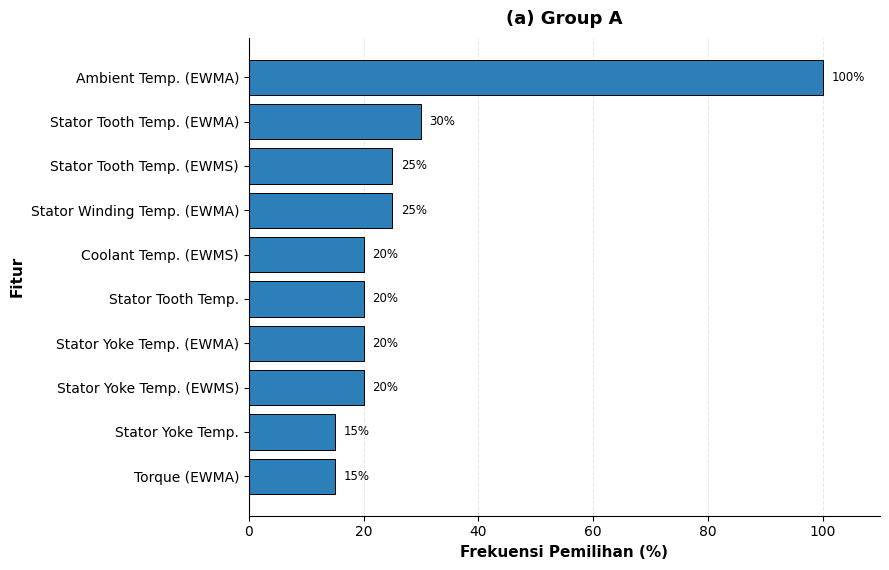

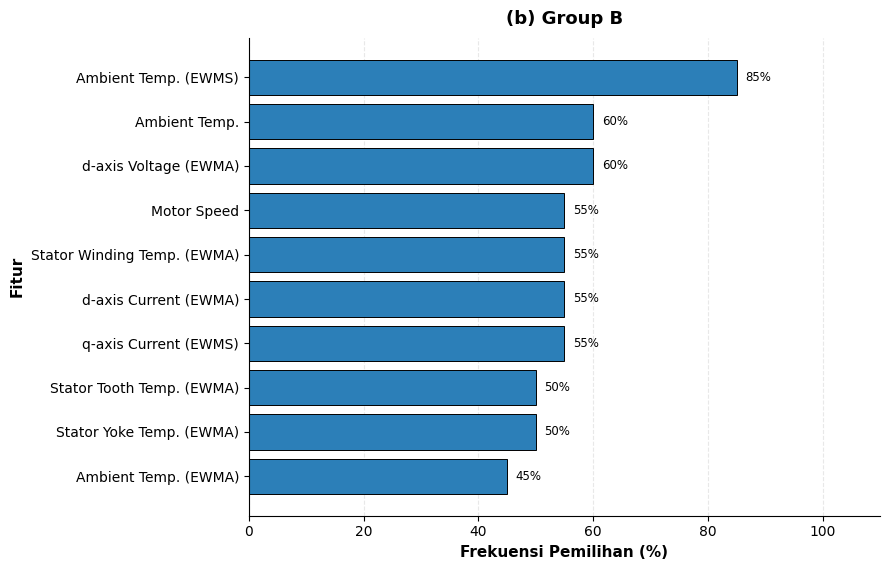


=== Lampiran Frekuensi Fitur - Group A ===
                    Feature  Count_A  Percentage_A
       Ambient Temp. (EWMA)       20         100.0
  Stator Tooth Temp. (EWMA)        6          30.0
  Stator Tooth Temp. (EWMS)        5          25.0
Stator Winding Temp. (EWMA)        5          25.0
       Coolant Temp. (EWMS)        4          20.0
         Stator Tooth Temp.        4          20.0
   Stator Yoke Temp. (EWMA)        4          20.0
   Stator Yoke Temp. (EWMS)        4          20.0
          Stator Yoke Temp.        3          15.0
              Torque (EWMA)        3          15.0
      q-axis Voltage (EWMA)        3          15.0
       Ambient Temp. (EWMS)        2          10.0
         Motor Speed (EWMA)        2          10.0
         Motor Speed (EWMS)        2          10.0
              Torque (EWMS)        2          10.0
      d-axis Voltage (EWMA)        2          10.0
      q-axis Current (EWMA)        2          10.0
      q-axis Voltage (EWMS)        2  

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter

# ============================================================
# 1. FUNGSI MEMPERBAIKI NAMA FITUR
# ============================================================

def clean_feature_name(name):
    mapping = {
        'u_d': 'd-axis Voltage',
        'u_q': 'q-axis Voltage',
        'i_d': 'd-axis Current',
        'i_q': 'q-axis Current',
        'coolant': 'Coolant Temp.',
        'stator_winding': 'Stator Winding Temp.',
        'stator_tooth': 'Stator Tooth Temp.',
        'stator_yoke': 'Stator Yoke Temp.',
        'motor_speed': 'Motor Speed',
        'ambient': 'Ambient Temp.',
        'torque': 'Torque'
    }

    if name in mapping:
        return mapping[name]

    parts = name.split('_')
    suffix = parts[-1].upper()
    base_name = '_'.join(parts[:-1])

    translated_base = mapping.get(
        base_name,
        base_name.replace('_', ' ').title()
    )

    return f"{translated_base} ({suffix})"

# ============================================================
# 2. HITUNG FREKUENSI FITUR TERPILIH
# ============================================================

def count_selected_features(run_results):
    return Counter(
        feature
        for run_data in run_results
        for feature in set(run_data['result']['Selected_Features_List'])
    )

feature_counts_a = count_selected_features(cv_a_afs)
feature_counts_b = count_selected_features(cv_b_afs)

n_runs_a = len(cv_a_afs)
n_runs_b = len(cv_b_afs)

if n_runs_a == 0 or n_runs_b == 0:
    raise ValueError("Hasil eksperimen AFS belum tersedia.")

# ============================================================
# 3. MEMBANGUN DATAFRAME FREKUENSI
# ============================================================

all_features = list(FEATURES_ENG)

df_freq = pd.DataFrame({
    'Original_Feature': all_features
})

df_freq['Count_A'] = df_freq['Original_Feature'].apply(lambda f: feature_counts_a[f])
df_freq['Count_B'] = df_freq['Original_Feature'].apply(lambda f: feature_counts_b[f])

df_freq['Percentage_A'] = (df_freq['Count_A'] / n_runs_a) * 100
df_freq['Percentage_B'] = (df_freq['Count_B'] / n_runs_b) * 100

df_freq['Feature'] = df_freq['Original_Feature'].apply(clean_feature_name)

# Data Group A
df_group_a = df_freq[['Feature', 'Count_A', 'Percentage_A']].copy()
df_group_a = df_group_a[df_group_a['Percentage_A'] > 0]
df_group_a = df_group_a.sort_values(
    by=['Percentage_A', 'Feature'],
    ascending=[False, True]
).head(10).reset_index(drop=True)

# Data Group B
df_group_b = df_freq[['Feature', 'Count_B', 'Percentage_B']].copy()
df_group_b = df_group_b[df_group_b['Percentage_B'] > 0]
df_group_b = df_group_b.sort_values(
    by=['Percentage_B', 'Feature'],
    ascending=[False, True]
).head(10).reset_index(drop=True)

# ============================================================
# 4. FUNGSI PLOT
# ============================================================

def plot_top_features(df_plot, percentage_col, title, filename):
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Liberation Sans']

    academic_color = '#2c7fb8'

    fig, ax = plt.subplots(figsize=(9, 5.8))

    bars = ax.barh(
        df_plot['Feature'],
        df_plot[percentage_col],
        color=academic_color,
        edgecolor='black',
        linewidth=0.7
    )

    # Frekuensi tertinggi di atas
    ax.invert_yaxis()

    # Judul singkat
    ax.set_title(
        title,
        fontsize=13,
        fontweight='bold',
        pad=10
    )

    ax.set_xlabel('Frekuensi Pemilihan (%)', fontsize=11, fontweight='semibold')
    ax.set_ylabel('Fitur', fontsize=11, fontweight='semibold')

    ax.set_xlim(0, 110)
    ax.set_xticks([0, 20, 40, 60, 80, 100])

    # Hanya grid vertikal
    ax.grid(False)
    ax.xaxis.grid(True, linestyle='--', alpha=0.35, color='#bfbfbf')
    ax.yaxis.grid(False)
    ax.set_axisbelow(True)

    # Label persentase
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 1.5,
            bar.get_y() + bar.get_height() / 2,
            f'{width:.0f}%',
            ha='left',
            va='center',
            fontsize=8.5
        )

    # Rapikan frame
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()

# ============================================================
# 5. BUAT GRAFIK
# ============================================================

plot_top_features(
    df_group_a,
    'Percentage_A',
    '(a) Group A',
    'Gambar_4_1a_Top10_Fitur_Group_A.png'
)

plot_top_features(
    df_group_b,
    'Percentage_B',
    '(b) Group B',
    'Gambar_4_1b_Top10_Fitur_Group_B.png'
)

# ============================================================
# 6. REKAP UNTUK LAMPIRAN
# ============================================================

df_lampiran_a = df_freq[['Feature', 'Count_A', 'Percentage_A']].copy()
df_lampiran_a = df_lampiran_a.sort_values(
    by=['Percentage_A', 'Feature'],
    ascending=[False, True]
).reset_index(drop=True)

df_lampiran_b = df_freq[['Feature', 'Count_B', 'Percentage_B']].copy()
df_lampiran_b = df_lampiran_b.sort_values(
    by=['Percentage_B', 'Feature'],
    ascending=[False, True]
).reset_index(drop=True)

print("\n=== Lampiran Frekuensi Fitur - Group A ===")
print(df_lampiran_a.to_string(index=False))

print("\n=== Lampiran Frekuensi Fitur - Group B ===")
print(df_lampiran_b.to_string(index=False))

print("\n✅ Grafik top 10 berhasil dibuat dengan label yang diperbaiki. Rekap lengkap seluruh fitur ditampilkan untuk lampiran.")

## **4.1.2	Analisis Stabilitas dan Konvergensi**

#### Kurva Konvergensi AFS (Feature Selection)

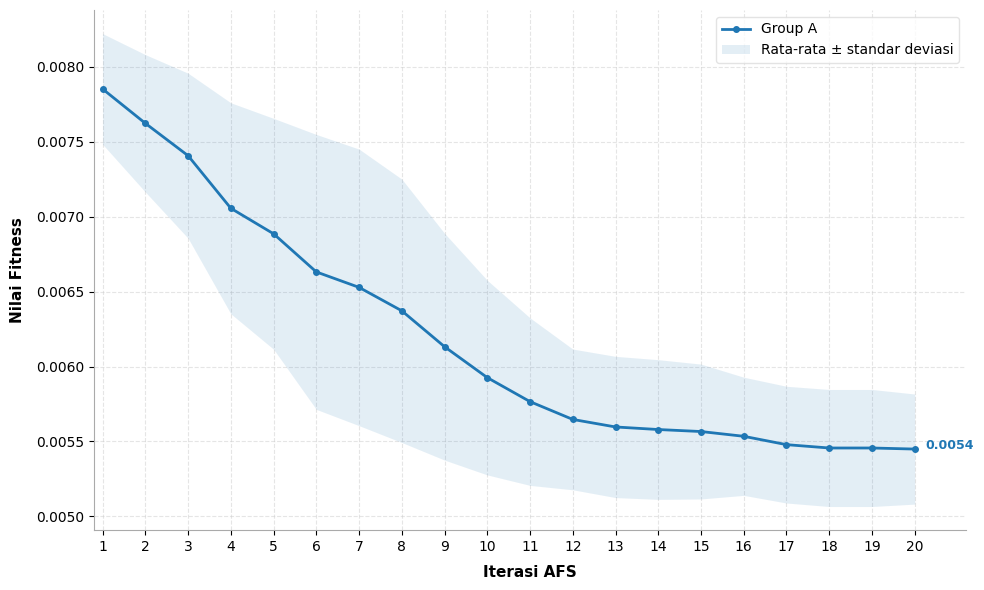

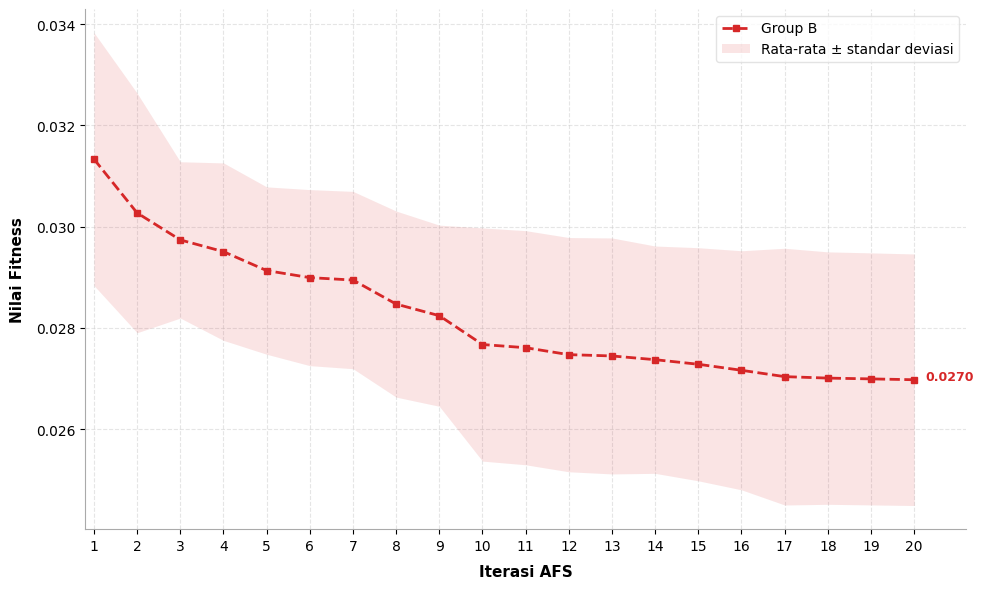

=== HASIL KONVERGENSI AFS ===
Jumlah Run Group A : 20
Jumlah Run Group B : 20
Fitness Akhir Group A : 0.0054 ± 0.0004
Fitness Akhir Group B : 0.0270 ± 0.0025

Grafik konvergensi AFS berhasil disimpan:
- Gambar_4_3_Konvergensi_AFS_Group_A.png
- Gambar_4_4_Konvergensi_AFS_Group_B.png


In [2]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# 1. MEMPERSIAPKAN DATA KONVERGENSI AFS
# ============================================================

def prepare_convergence(run_results, group_name):

    conv_list = []

    for i, run_data in enumerate(run_results, start=1):
        conv = run_data.get('afs_conv')

        if conv is None or len(conv) == 0:
            raise ValueError(
                f"{group_name}, run {i}: data konvergensi kosong."
            )

        conv = np.asarray(conv, dtype=float).ravel()

        if not np.all(np.isfinite(conv)):
            raise ValueError(
                f"{group_name}, run {i}: data mengandung NaN/Inf."
            )

        conv_list.append(conv)

    if not conv_list:
        raise ValueError(
            f"Hasil konvergensi {group_name} tidak tersedia."
        )

    # Memastikan jumlah iterasi konsisten
    lengths = [len(conv) for conv in conv_list]

    if any(length != AFS_ITERATIONS for length in lengths):
        raise ValueError(
            f"Panjang kurva {group_name} tidak sesuai "
            f"dengan AFS_ITERATIONS={AFS_ITERATIONS}. "
            f"Panjang aktual: {lengths}"
        )

    conv_array = np.vstack(conv_list)

    # Memeriksa kurva global best fitness
    if np.any(np.diff(conv_array, axis=1) > 1e-9):
        print(
            f"Peringatan: kurva {group_name} tidak selalu "
            "menurun. Periksa pencatatan global best fitness."
        )

    # Rata-rata dan standar deviasi antar-run
    mean_conv = np.mean(conv_array, axis=0)
    std_conv = np.std(conv_array, axis=0)

    return mean_conv, std_conv, len(conv_list)


# ============================================================
# 2. MENGHITUNG RATA-RATA DAN STANDAR DEVIASI
# ============================================================

mean_a, std_a, n_a = prepare_convergence(
    cv_a_afs, "Group A"
)

mean_b, std_b, n_b = prepare_convergence(
    cv_b_afs, "Group B"
)

iterations_afs = np.arange(1, AFS_ITERATIONS + 1)


# ============================================================
# 3. KONFIGURASI VISUALISASI AKADEMIK
# ============================================================

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [
    'DejaVu Sans', 'Arial', 'Liberation Sans'
]

color_a = '#1f77b4'
color_b = '#d62728'


# ============================================================
# 4. FUNGSI UNTUK MEMBUAT SATU GRAFIK KONVERGENSI
# ============================================================

def plot_single_convergence(
    iterations,
    mean_conv,
    std_conv,
    group_name,
    color,
    marker,
    linestyle,
    save_name
):
    fig, ax = plt.subplots(figsize=(10, 6))

    # Kurva rata-rata fitness
    ax.plot(
        iterations,
        mean_conv,
        label=group_name,
        color=color,
        marker=marker,
        markersize=4,
        linewidth=2,
        linestyle=linestyle
    )

    # Area standar deviasi
    ax.fill_between(
        iterations,
        mean_conv - std_conv,
        mean_conv + std_conv,
        color=color,
        alpha=0.12,
        linewidth=0,
        label='Rata-rata ± standar deviasi'
    )

    # Anotasi fitness akhir
    ax.annotate(
        f'{mean_conv[-1]:.4f}',
        xy=(iterations[-1], mean_conv[-1]),
        xytext=(8, 0),
        textcoords='offset points',
        color=color,
        fontsize=9,
        fontweight='bold'
    )

    # Label sumbu
    ax.set_xlabel(
        'Iterasi AFS',
        fontsize=11,
        fontweight='semibold',
        labelpad=8
    )

    ax.set_ylabel(
        'Nilai Fitness',
        fontsize=11,
        fontweight='semibold',
        labelpad=8
    )

    # Menampilkan seluruh iterasi
    ax.set_xticks(iterations)
    ax.set_xlim(0.8, AFS_ITERATIONS + 1.2)

    # Garis kisi
    ax.grid(
        True,
        axis='both',
        linestyle='--',
        alpha=0.5,
        color='#cccccc'
    )
    ax.set_axisbelow(True)

    # Merapikan bingkai
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#aaaaaa')
    ax.spines['bottom'].set_color('#aaaaaa')

    # Legenda
    ax.legend(
        loc='upper right',
        frameon=True,
        edgecolor='#dddddd',
        fontsize=10
    )

    plt.tight_layout()

    plt.savefig(
        save_name,
        dpi=300,
        bbox_inches='tight',
        facecolor='white'
    )

    plt.show()


# ============================================================
# 5. MEMBUAT GRAFIK GROUP A
# ============================================================

plot_single_convergence(
    iterations=iterations_afs,
    mean_conv=mean_a,
    std_conv=std_a,
    group_name='Group A',
    color=color_a,
    marker='o',
    linestyle='-',
    save_name='Gambar_4_3_Konvergensi_AFS_Group_A.png'
)


# ============================================================
# 6. MEMBUAT GRAFIK GROUP B
# ============================================================

plot_single_convergence(
    iterations=iterations_afs,
    mean_conv=mean_b,
    std_conv=std_b,
    group_name='Group B',
    color=color_b,
    marker='s',
    linestyle='--',
    save_name='Gambar_4_4_Konvergensi_AFS_Group_B.png'
)


# ============================================================
# 7. MENAMPILKAN RINGKASAN KONVERGENSI
# ============================================================

print("=== HASIL KONVERGENSI AFS ===")

print(f"Jumlah Run Group A : {n_a}")
print(f"Jumlah Run Group B : {n_b}")

print(
    f"Fitness Akhir Group A : "
    f"{mean_a[-1]:.4f} ± {std_a[-1]:.4f}"
)

print(
    f"Fitness Akhir Group B : "
    f"{mean_b[-1]:.4f} ± {std_b[-1]:.4f}"
)

print("\nGrafik konvergensi AFS berhasil disimpan:")
print("- Gambar_4_3_Konvergensi_AFS_Group_A.png")
print("- Gambar_4_4_Konvergensi_AFS_Group_B.png")

### Indeks Jaccard

In [ ]:

import numpy as np
import pandas as pd
from itertools import combinations

# ============================================================
# 1. MENGAMBIL SUBSET FITUR DARI SETIAP RUN
# ============================================================

def extract_feature_subsets(run_results, group_name):

    subsets = []

    for i, run_data in enumerate(run_results, start=1):

        selected_features = run_data[
            'result'
        ]['Selected_Features_List']

        # Mengubah daftar fitur menjadi himpunan
        subset = frozenset(selected_features)

        if len(subset) == 0:
            raise ValueError(
                f"{group_name}, Run {i}: subset fitur kosong."
            )

        subsets.append(subset)

    if len(subsets) < 2:
        raise ValueError(
            f"{group_name} membutuhkan minimal 2 run."
        )

    return subsets


# ============================================================
# 2. FUNGSI INDEKS JACCARD
# ============================================================

def jaccard_similarity(subset_a, subset_b):

    intersection = len(subset_a.intersection(subset_b))
    union = len(subset_a.union(subset_b))

    return intersection / union


# ============================================================
# 3. MENGHITUNG STABILITAS SUBSET FITUR
# ============================================================

def calculate_subset_stability(run_results, group_name):

    subsets = extract_feature_subsets(
        run_results, group_name
    )

    # Menghitung jumlah kombinasi subset unik
    unique_subsets = set(subsets)
    n_unique = len(unique_subsets)

    # Menghitung Jaccard untuk seluruh pasangan run
    jaccard_values = [
        jaccard_similarity(a, b)
        for a, b in combinations(subsets, 2)
    ]

    # Rata-rata kesamaan subset
    mean_jaccard = np.mean(jaccard_values)

    return {
        'Kelompok': group_name,
        'Jumlah Run': len(subsets),
        'Subset Unik': n_unique,
        'Rata-rata Jaccard': mean_jaccard,
        'Jumlah Pasangan': len(jaccard_values)
    }


# ============================================================
# 4. MENGHITUNG HASIL GROUP A DAN GROUP B
# ============================================================

result_a = calculate_subset_stability(
    cv_a_afs, 'Group A'
)

result_b = calculate_subset_stability(
    cv_b_afs, 'Group B'
)


# ============================================================
# 5. MENYUSUN TABEL 4.2
# ============================================================

df_stability = pd.DataFrame([
    result_a,
    result_b
])

# Kolom utama untuk tabel tesis
tabel_4_2 = df_stability[[
    'Kelompok',
    'Jumlah Run',
    'Subset Unik',
    'Rata-rata Jaccard'
]].copy()

tabel_4_2 = tabel_4_2.rename(columns={
    'Subset Unik': 'Kombinasi Subset Unik'
})

# Menampilkan hasil dengan 3 angka desimal
print("\n" + "=" * 65)
print("TABEL 4.2 STABILITAS SUBSET FITUR HASIL AFS")
print("=" * 65)

print(
    tabel_4_2.to_string(
        index=False,
        formatters={
            'Rata-rata Jaccard': lambda x: f'{x:.3f}'
        }
    )
)

# ============================================================
# 6. INFORMASI TAMBAHAN
# ============================================================

print("\n=== RINGKASAN PERHITUNGAN ===")

for result in [result_a, result_b]:

    print(f"\n{result['Kelompok']}")
    print(f"Jumlah run             : {result['Jumlah Run']}")
    print(f"Kombinasi subset unik  : {result['Subset Unik']}")
    print(f"Jumlah pasangan subset : {result['Jumlah Pasangan']}")
    print(
        f"Rata-rata Jaccard      : "
        f"{result['Rata-rata Jaccard']:.4f}"
    )


# ============================================================
# 7. MENYIMPAN HASIL TABEL
# ============================================================

tabel_4_2.to_csv(
    'Tabel_4_2_Stabilitas_Subset_AFS.csv',
    index=False,
    encoding='utf-8-sig',
    float_format='%.4f'
)

print("\nTabel 4.2 berhasil dihitung dan disimpan.")



TABEL 4.2 STABILITAS SUBSET FITUR HASIL AFS
Kelompok  Jumlah Run  Kombinasi Subset Unik Rata-rata Jaccard
 Group A          20                     20             0.224
 Group B          20                     20             0.270

=== RINGKASAN PERHITUNGAN ===

Group A
Jumlah run             : 20
Kombinasi subset unik  : 20
Jumlah pasangan subset : 190
Rata-rata Jaccard      : 0.2238

Group B
Jumlah run             : 20
Kombinasi subset unik  : 20
Jumlah pasangan subset : 190
Rata-rata Jaccard      : 0.2705

Tabel 4.2 berhasil dihitung dan disimpan.


# **4.2    Hasil Pemodelan RIME-XGBoost**

## **4.2.1	Hasil Optimasi Hyperparameter**

VALIDASI HASIL EKSPERIMEN
Group A Baseline: 20 run, 20 iterasi
Group A AFS: 20 run, 20 iterasi
Group B Baseline: 20 run, 20 iterasi
Group B AFS: 20 run, 20 iterasi

TABEL 4.3
RINGKASAN HIPERPARAMETER HASIL OPTIMASI RIME-XGBOOST


,Hiperparameter,Group A Baseline,Group A AFS,Group B Baseline,Group B AFS
0,n_estimators,"294,5 [212–300]",300 [268–300],"208,5 [80–300]","182,5 [115–300]"
1,max_depth,6 [6–6],6 [5–6],5 [4–6],6 [3–6]
2,learning_rate,"0,0667 [0,0332–0,0959]","0,1185 [0,0535–0,1200]","0,0565 [0,0200–0,1067]","0,0609 [0,0200–0,1200]"
3,min_child_weight,"2,76 [2,00–7,86]","2,02 [2,00–7,59]","2,50 [2,00–3,91]","2,67 [2,00–7,49]"
4,reg_lambda,"1,00 [1,00–22,91]","1,67 [1,00–29,94]","1,19 [1,00–16,91]","7,00 [1,00–18,72]"


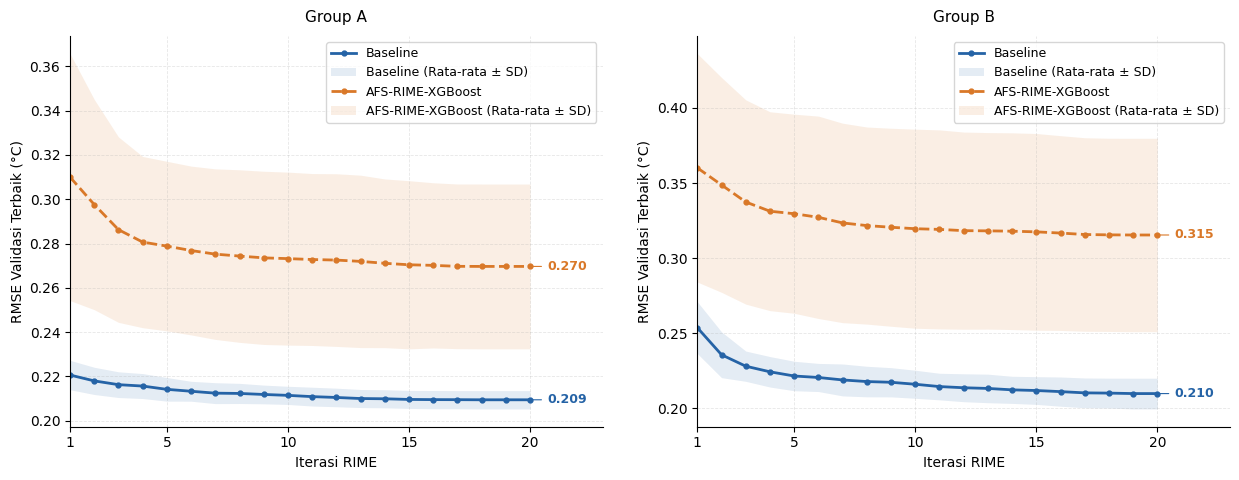


RINGKASAN KONVERGENSI RIME

Group A Baseline
------------------------------------------------
Jumlah run                 : 20
Jumlah iterasi             : 20
Rata-rata RMSE awal        : 0.2206 °C
Rata-rata RMSE akhir       : 0.2094 °C
Std. deviasi RMSE akhir    : 0.0041 °C
Rata-rata RMSE seluruh iterasi: 0.2122 °C

Group A AFS
------------------------------------------------
Jumlah run                 : 20
Jumlah iterasi             : 20
Rata-rata RMSE awal        : 0.3100 °C
Rata-rata RMSE akhir       : 0.2697 °C
Std. deviasi RMSE akhir    : 0.0372 °C
Rata-rata RMSE seluruh iterasi: 0.2767 °C

Group B Baseline
------------------------------------------------
Jumlah run                 : 20
Jumlah iterasi             : 20
Rata-rata RMSE awal        : 0.2537 °C
Rata-rata RMSE akhir       : 0.2099 °C
Std. deviasi RMSE akhir    : 0.0102 °C
Rata-rata RMSE seluruh iterasi: 0.2186 °C

Group B AFS
------------------------------------------------
Jumlah run                 : 20
Jumlah iteras

In [4]:

# ============================================================
# BAB IV - SUBBAB 4.2.1 (REVISI)
# TABEL 4.3 : RINGKASAN HIPERPARAMETER HASIL OPTIMASI
# GAMBAR 4.3: KURVA KONVERGENSI RIME-XGBOOST
#
# REVISI:
# 1. RMSE validasi dihapus dari Tabel 4.3
# 2. Angka RMSE akhir ditambahkan di ujung kurva
# 3. Hiperparameter menggunakan median [minimum-maksimum]
# 4. Ringkasan konvergensi menampilkan rata-rata RMSE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# ============================================================
# 1. KONFIGURASI
# ============================================================

N_RUNS_EXPECTED = 20
N_ITER_EXPECTED = 20

SAVE_DIR = Path("Hasil_BAB_IV")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

SCENARIOS = {
    "Group A Baseline": cv_a_base,
    "Group A AFS": cv_a_afs,
    "Group B Baseline": cv_b_base,
    "Group B AFS": cv_b_afs
}

PARAMETERS = [
    "n_estimators",
    "max_depth",
    "learning_rate",
    "min_child_weight",
    "reg_lambda"
]

# ============================================================
# 2. MENGAMBIL HASIL DARI 20 RUN
# ============================================================

hp_records = []
curves = {}

for scenario_name, runs in SCENARIOS.items():

    if len(runs) != N_RUNS_EXPECTED:
        raise ValueError(
            f"{scenario_name}: ditemukan {len(runs)} run. "
            f"Seharusnya {N_RUNS_EXPECTED} run."
        )

    convergence_data = []

    for run_no, run_data in enumerate(runs, start=1):

        result = run_data["result"]
        best_hp = result["best_hp"]

        # Riwayat fitness RIME (RMSE validasi)
        conv = np.asarray(
            run_data["rime_conv"],
            dtype=float
        ).reshape(-1)

        if len(conv) != N_ITER_EXPECTED:
            raise ValueError(
                f"{scenario_name}, run {run_no}: "
                f"ditemukan {len(conv)} iterasi."
            )

        if not np.all(np.isfinite(conv)):
            raise ValueError(
                f"{scenario_name}, run {run_no}: "
                "nilai konvergensi tidak valid."
            )

        convergence_data.append(conv)

        record = {
            "Skenario": scenario_name,
            "Run": run_no,
            "Seed": result.get("Seed", np.nan)
        }

        for param in PARAMETERS:

            if param not in best_hp:
                raise KeyError(
                    f"{scenario_name}, run {run_no}: "
                    f"parameter {param} tidak ditemukan."
                )

            record[param] = float(best_hp[param])

        record["RMSE_Validasi_Akhir"] = float(conv[-1])

        hp_records.append(record)

    curves[scenario_name] = np.vstack(
        convergence_data
    )

df_hp = pd.DataFrame(hp_records)

print("=" * 65)
print("VALIDASI HASIL EKSPERIMEN")
print("=" * 65)

for name, data in curves.items():
    print(
        f"{name}: "
        f"{data.shape[0]} run, "
        f"{data.shape[1]} iterasi"
    )

# ============================================================
# 3. TABEL 4.3
# MEDIAN [MINIMUM-MAKSIMUM]
# ============================================================

def format_num(value, decimals=2):
    return f"{value:.{decimals}f}".replace(".", ",")


def summarize_parameter(values, param):

    median = float(np.median(values))
    minimum = float(np.min(values))
    maximum = float(np.max(values))

    if param in ["n_estimators", "max_depth"]:

        # Median dapat pecahan jika jumlah run genap
        dec = 0 if median.is_integer() else 1

        med = format_num(median, dec)
        low = str(int(round(minimum)))
        high = str(int(round(maximum)))

    elif param == "learning_rate":

        med = format_num(median, 4)
        low = format_num(minimum, 4)
        high = format_num(maximum, 4)

    else:

        med = format_num(median, 2)
        low = format_num(minimum, 2)
        high = format_num(maximum, 2)

    return f"{med} [{low}–{high}]"


rows = []

for param in PARAMETERS:

    row = {"Hiperparameter": param}

    for scenario_name in SCENARIOS:

        values = df_hp.loc[
            df_hp["Skenario"] == scenario_name,
            param
        ].to_numpy(dtype=float)

        row[scenario_name] = summarize_parameter(
            values,
            param
        )

    rows.append(row)

tabel_43 = pd.DataFrame(rows)

print("\n" + "=" * 65)
print("TABEL 4.3")
print("RINGKASAN HIPERPARAMETER HASIL OPTIMASI RIME-XGBOOST")
print("=" * 65)

display(tabel_43)

# Simpan tabel utama
tabel_43.to_csv(
    SAVE_DIR / "Tabel_4_3_Hiperparameter_RIME.csv",
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

# Simpan rincian setiap run untuk lampiran
df_hp.to_csv(
    SAVE_DIR / "Lampiran_Hiperparameter_Per_Run.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 4. HITUNG STATISTIK KONVERGENSI
# ============================================================

conv_records = []
summary_records = []

for scenario_name, data in curves.items():

    mean_curve = np.mean(data, axis=0)
    std_curve = np.std(data, axis=0, ddof=1)

    # Rata-rata RMSE pada iterasi pertama
    mean_initial = float(mean_curve[0])

    # Rata-rata RMSE akhir dari seluruh run
    mean_final = float(mean_curve[-1])

    # Standar deviasi RMSE akhir antarrun
    std_final = float(std_curve[-1])

    # Rata-rata semua nilai pada riwayat konvergensi
    mean_all_iterations = float(np.mean(data))

    summary_records.append({
        "Skenario": scenario_name,
        "Jumlah_Run": data.shape[0],
        "Jumlah_Iterasi": data.shape[1],
        "Rata_Rata_RMSE_Awal": mean_initial,
        "Rata_Rata_RMSE_Akhir": mean_final,
        "Std_RMSE_Akhir": std_final,
        "Rata_Rata_RMSE_Sepanjang_Iterasi":
            mean_all_iterations
    })

    for i in range(data.shape[1]):

        conv_records.append({
            "Skenario": scenario_name,
            "Iterasi": i + 1,
            "Mean_RMSE": float(mean_curve[i]),
            "Std_RMSE": float(std_curve[i])
        })

df_conv = pd.DataFrame(conv_records)
df_summary = pd.DataFrame(summary_records)

# ============================================================
# 5. GAMBAR 4.3 - KURVA KONVERGENSI RIME
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 10,
    "legend.fontsize": 9
})

iterations = np.arange(
    1, N_ITER_EXPECTED + 1
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.5, 4.9)
)

COLORS = {
    "Baseline": "#2563A6",
    "AFS": "#D97828"
}

plot_config = [
    (
        axes[0],
        "Group A",
        "Group A Baseline",
        "Group A AFS"
    ),
    (
        axes[1],
        "Group B",
        "Group B Baseline",
        "Group B AFS"
    )
]

for ax, group_name, base_name, afs_name in plot_config:

    series = [
        (
            base_name,
            "Baseline",
            COLORS["Baseline"],
            "-"
        ),
        (
            afs_name,
            "AFS-RIME-XGBoost",
            COLORS["AFS"],
            "--"
        )
    ]

    endpoints = []

    for scenario_name, label, color, style in series:

        data = curves[scenario_name]

        mean_curve = np.mean(data, axis=0)
        std_curve = np.std(data, axis=0, ddof=1)

        # Garis konvergensi
        ax.plot(
            iterations,
            mean_curve,
            color=color,
            linestyle=style,
            linewidth=2,
            marker="o",
            markersize=3.5,
            label=label
        )
        # Area standar deviasi
        ax.fill_between(
            iterations,
            mean_curve - std_curve,
            mean_curve + std_curve,
            color=color,
            alpha=0.12,
            linewidth=0,
            label=f"{label} (Rata-rata ± SD)"
        )

        endpoints.append({
            "value": float(mean_curve[-1]),
            "color": color
        })

    # --------------------------------------------------------
    # Label nilai RMSE pada ujung terakhir kurva
    # --------------------------------------------------------

    # Beri ruang di sebelah kanan untuk angka
    ax.set_xlim(1, N_ITER_EXPECTED + 3)

    ymin, ymax = ax.get_ylim()
    yrange = ymax - ymin

    # Jarak minimum antardua label
    min_gap = max(0.06 * yrange, 1e-8)

    endpoints = sorted(
        endpoints,
        key=lambda item: item["value"]
    )

    label_positions = []
    previous_y = None

    for item in endpoints:

        y = item["value"]

        if previous_y is not None:
            y = max(y, previous_y + min_gap)

        label_positions.append(y)
        previous_y = y

    # Perluas batas Y bila diperlukan
    top_required = max(label_positions) + min_gap

    if top_required > ymax:
        ax.set_ylim(
            ymin,
            top_required
        )

    # Tulis angka di kanan titik terakhir
    for item, label_y in zip(
        endpoints,
        label_positions
    ):

        final_value = item["value"]

        ax.annotate(
            f"{final_value:.3f}",
            xy=(
                N_ITER_EXPECTED,
                final_value
            ),
            xytext=(
                N_ITER_EXPECTED + 0.7,
                label_y
            ),
            textcoords="data",
            fontsize=9,
            fontweight="bold",
            color=item["color"],
            ha="left",
            va="center",
            arrowprops={
                "arrowstyle": "-",
                "color": item["color"],
                "linewidth": 0.8
            }
        )

    ax.set_title(
        group_name,
        fontsize=11,
        pad=10
    )

    ax.set_xlabel("Iterasi RIME")
    ax.set_ylabel("RMSE Validasi Terbaik (°C)")

    ax.set_xticks([1, 5, 10, 15, 20])

    ax.grid(
        True,
        linestyle="--",
        linewidth=0.6,
        alpha=0.3
    )

    ax.legend(
        loc="upper right",
        frameon=True
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout(w_pad=2.5)

png_path = (
    SAVE_DIR /
    "Gambar_4_3_Konvergensi_RIME_XGBoost.png"
)

pdf_path = (
    SAVE_DIR /
    "Gambar_4_3_Konvergensi_RIME_XGBoost.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 6. RINGKASAN KONVERGENSI RIME
# ============================================================

print("\n" + "=" * 70)
print("RINGKASAN KONVERGENSI RIME")
print("=" * 70)

for _, row in df_summary.iterrows():

    print(f"\n{row['Skenario']}")
    print("-" * 48)

    print(
        f"Jumlah run                 : "
        f"{int(row['Jumlah_Run'])}"
    )

    print(
        f"Jumlah iterasi             : "
        f"{int(row['Jumlah_Iterasi'])}"
    )

    print(
        f"Rata-rata RMSE awal        : "
        f"{row['Rata_Rata_RMSE_Awal']:.4f} °C"
    )

    print(
        f"Rata-rata RMSE akhir       : "
        f"{row['Rata_Rata_RMSE_Akhir']:.4f} °C"
    )

    print(
        f"Std. deviasi RMSE akhir    : "
        f"{row['Std_RMSE_Akhir']:.4f} °C"
    )

    print(
        f"Rata-rata RMSE seluruh "
        f"iterasi: "
        f"{row['Rata_Rata_RMSE_Sepanjang_Iterasi']:.4f} °C"
    )

# ============================================================
# 7. SIMPAN RINGKASAN DAN DATA KURVA
# ============================================================

df_summary.to_csv(
    SAVE_DIR / "Ringkasan_Konvergensi_RIME.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.6f"
)

df_conv.to_csv(
    SAVE_DIR / "Data_Konvergensi_RIME.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.6f"
)

print("\n" + "=" * 70)
print("SEMUA HASIL SUBBAB 4.2.1 BERHASIL DIBUAT")
print("=" * 70)

print(f"Folder: {SAVE_DIR.resolve()}")

print("\nFile tersimpan:")
print("1. Tabel_4_3_Hiperparameter_RIME.csv")
print("2. Lampiran_Hiperparameter_Per_Run.csv")
print("3. Gambar_4_3_Konvergensi_RIME_XGBoost.png")
print("4. Gambar_4_3_Konvergensi_RIME_XGBoost.pdf")
print("5. Ringkasan_Konvergensi_RIME.csv")
print("6. Data_Konvergensi_RIME.csv")


In [ ]:
param_results = []

for cv_list, experiment_name in [
    (cv_a_base, "Group A Baseline"),
    (cv_a_afs, "Group A + AFS"),
    (cv_b_base, "Group B Baseline"),
    (cv_b_afs, "Group B + AFS"),
]:
    for run_idx, run_data in enumerate(cv_list, 1):
        best_hp = run_data['result']['best_hp']
        param_results.append({
            'Eksperimen': experiment_name,
            'Run': run_idx,
            'n_estimators': best_hp['n_estimators'],
            'max_depth': best_hp['max_depth'],
            'learning_rate': best_hp['learning_rate']
        })

param_df = pd.DataFrame(param_results)

# Group by Experiment and calculate descriptive statistics
param_summary_tbl = param_df.groupby('Eksperimen').agg(
    N_Estimators_Mean=('n_estimators', 'mean'),
    N_Estimators_Median=('n_estimators', 'median'),
    N_Estimators_STD=('n_estimators', 'std'),
    Max_Depth_Mean=('max_depth', 'mean'),
    Max_Depth_Median=('max_depth', 'median'),
    Max_Depth_STD=('max_depth', 'std'),
    Learning_Rate_Mean=('learning_rate', 'mean'),
    Learning_Rate_Median=('learning_rate', 'median'),
    Learning_Rate_STD=('learning_rate', 'std')
).round(4)

display(param_summary_tbl)

print("✅ Tabel parameter model berhasil dibuat dan ditampilkan.")

,N_Estimators_Mean,N_Estimators_Median,N_Estimators_STD,Max_Depth_Mean,Max_Depth_Median,Max_Depth_STD,Learning_Rate_Mean,Learning_Rate_Median,Learning_Rate_STD
Eksperimen,,,,,,,,,
Group A + AFS,297.9,300.0,7.2685,5.90,6.0,0.3078,0.1128,0.1185,0.0153
Group A Baseline,282.0,294.5,26.5885,6.00,6.0,0.0000,0.0646,0.0667,0.0203
Group B + AFS,212.8,182.5,69.9689,5.35,6.0,0.9333,0.0641,0.0609,0.0353
Group B Baseline,203.3,208.5,62.7099,4.80,5.0,0.7678,0.0573,0.0565,0.0252


✅ Tabel parameter model berhasil dibuat dan ditampilkan.


In [ ]:
# Ekstrak Riwayat Fitness per Iterasi (Convergence History) dari Binary-RIME AFS
# Ini adalah rata-rata dari semua runs
print("--- Riwayat Fitness per Iterasi (Convergence History) AFS (Group A) ---")
# cv_a_afs already contains afs_conv for each run
# We need to average these across all runs, as the user requested 'minimal satu run representatif'
# For now, let's show the mean convergence across all runs.
if cv_a_afs and cv_a_afs[0]['afs_conv']:
    afs_conv_a_lists = [run_data['afs_conv'] for run_data in cv_a_afs if run_data['afs_conv']]
    if afs_conv_a_lists:
        mean_afs_conv_a = np.mean(np.array(afs_conv_a_lists), axis=0)
        print(f"Group A AFS Convergence (Mean across {N_RUNS} runs): {mean_afs_conv_a.tolist()}")
    else:
        print("No AFS convergence data available for Group A.")
else:
    print("No AFS convergence data available for Group A.")

print("\n--- Riwayat Fitness per Iterasi (Convergence History) AFS (Group B) ---")
if cv_b_afs and cv_b_afs[0]['afs_conv']:
    afs_conv_b_lists = [run_data['afs_conv'] for run_data in cv_b_afs if run_data['afs_conv']]
    if afs_conv_b_lists:
        mean_afs_conv_b = np.mean(np.array(afs_conv_b_lists), axis=0)
        print(f"Group B AFS Convergence (Mean across {N_RUNS} runs): {mean_afs_conv_b.tolist()}")
    else:
        print("No AFS convergence data available for Group B.")
else:
    print("No AFS convergence data available for Group B.")


# Ekstrak Daftar Fitur Terpilih per Run
print("\n--- Daftar Fitur Terpilih per Run (Group A + AFS) ---")
for i, run_data in enumerate(cv_a_afs):
    selected_features = run_data['result']['Selected_Features_List']
    print(f"Run {i+1}: {selected_features}")

print("\n--- Daftar Fitur Terpilih per Run (Group B + AFS) ---")
for i, run_data in enumerate(cv_b_afs):
    selected_features = run_data['result']['Selected_Features_List']
    print(f"Run {i+1}: {selected_features}")


--- Riwayat Fitness per Iterasi (Convergence History) AFS (Group A) ---
Group A AFS Convergence (Mean across 20 runs): [0.007853008334180402, 0.007623826449869281, 0.0074076393519948245, 0.007056541993449914, 0.006886321526030121, 0.006631804490322121, 0.006528718266751389, 0.0063722567112326055, 0.006132634507584321, 0.00592629893604057, 0.0057660079372105575, 0.005647115290385541, 0.005596873520811821, 0.005579781993950256, 0.005566391448585702, 0.005534615620969503, 0.005478832475224191, 0.005456478214070488, 0.005456478214070488, 0.005449361122579476]

--- Riwayat Fitness per Iterasi (Convergence History) AFS (Group B) ---
Group B AFS Convergence (Mean across 20 runs): [0.03133271108456736, 0.030268967042619645, 0.029736540654519382, 0.029504427297911213, 0.029130638404619373, 0.02899140257134471, 0.028943432177121874, 0.028468745407426978, 0.028239170114475604, 0.027669931612367766, 0.027606883952357202, 0.02746985383411858, 0.027444097924264766, 0.027370287217871776, 0.0272798308

In [ ]:
import platform
import pandas as pd
import sklearn
import xgboost as xgb

print("Python Version :", platform.python_version())
print("Pandas Version :", pd.__version__)
print("Scikit-Learn   :", sklearn.__version__)
print("XGBoost        :", xgb.__version__)

Python Version : 3.13.18
Pandas Version : 2.2.3
Scikit-Learn   : 1.6.1
XGBoost        : 3.4.1


## **4.2.2    Hasil Estimasi Temperatur Rotor PMSM**

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== SEED REPRESENTATIF ===
Group A: 46
Group B: 45


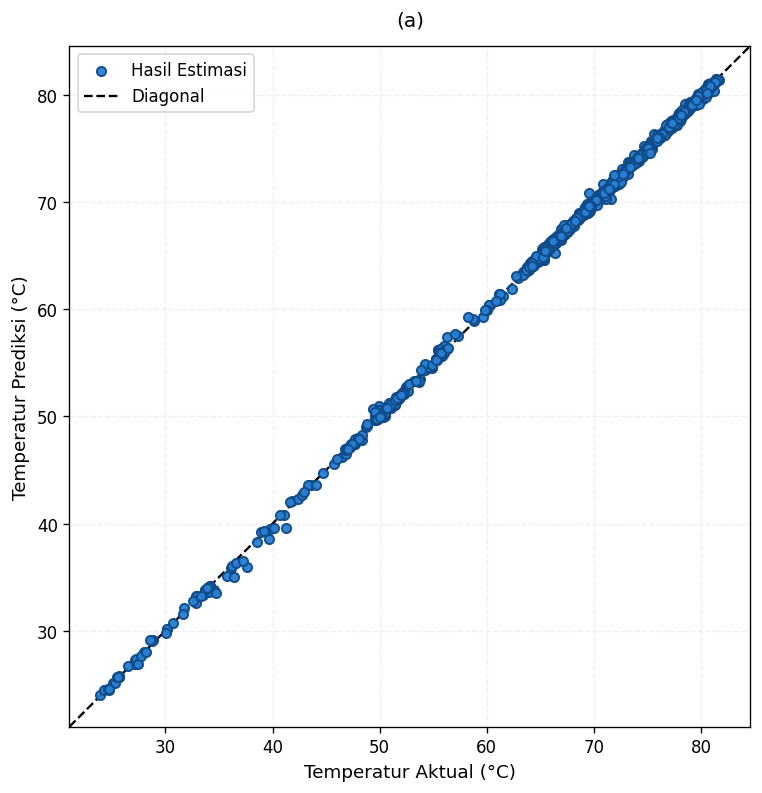

Berhasil: Gambar_4_4_a_Group_A_Baseline


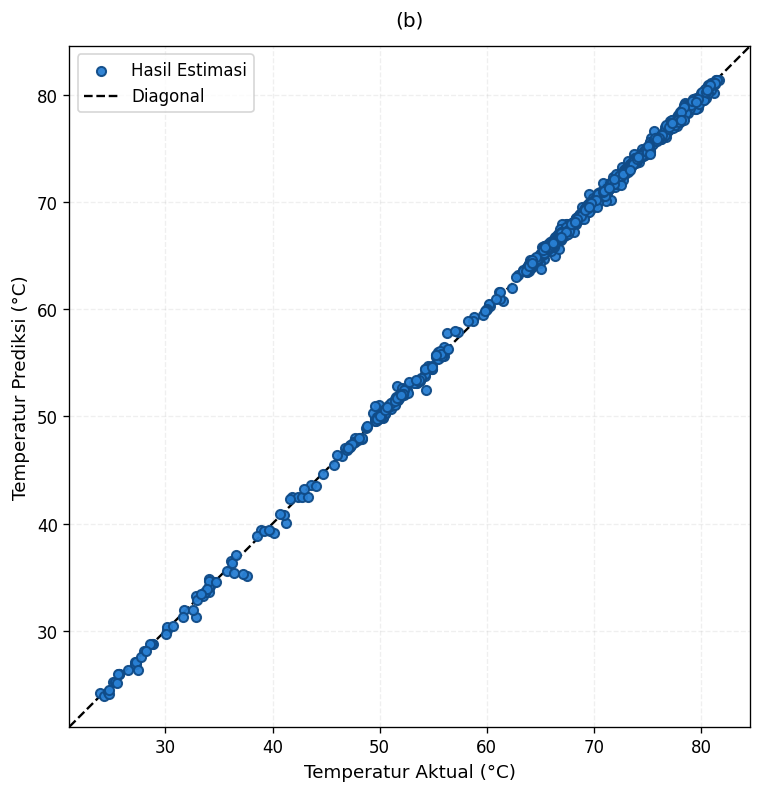

Berhasil: Gambar_4_4_b_Group_A_AFS_RIME_XGBoost


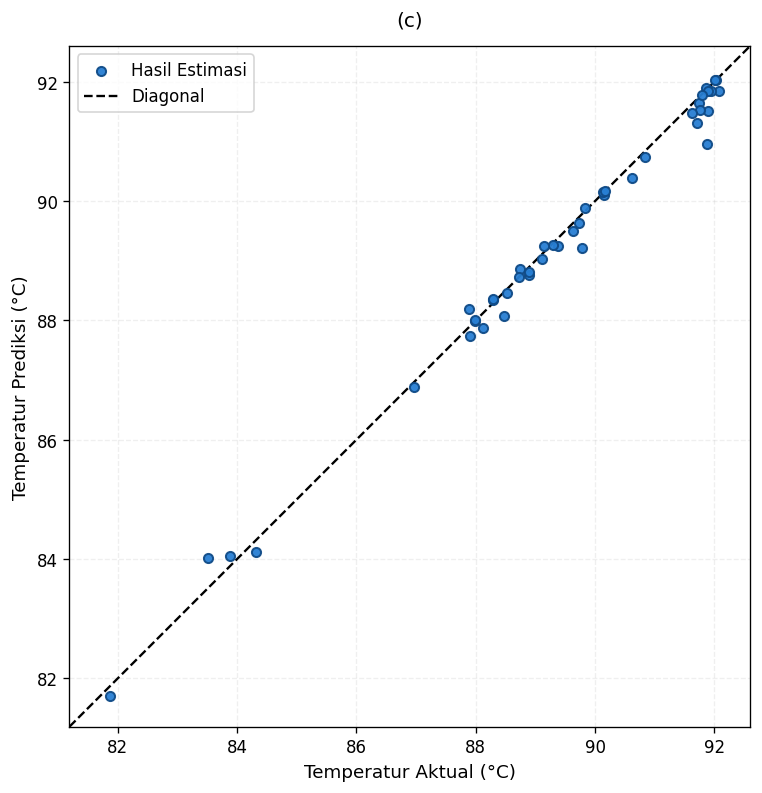

Berhasil: Gambar_4_4_c_Group_B_Baseline


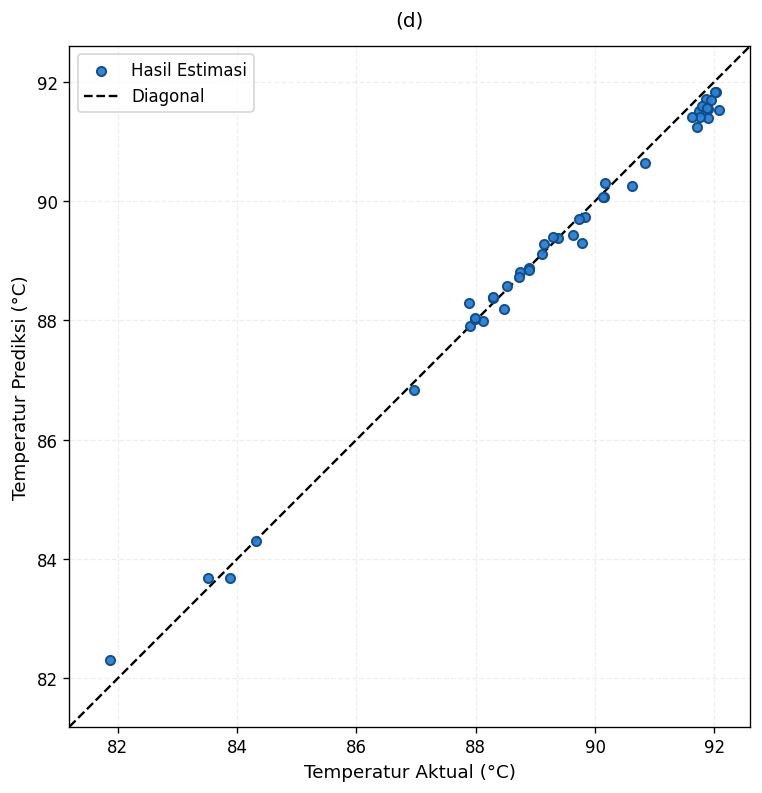

Berhasil: Gambar_4_4_d_Group_B_AFS_RIME_XGBoost

SELURUH PARITY PLOT BERHASIL DIBUAT
Seed Group A: 46
Seed Group B: 45
Jumlah sampel uji Group A: 1430
Jumlah sampel uji Group B: 44
Lokasi penyimpanan: /content/drive/MyDrive/AFS_RIME_XGBoost/Hasil_BAB_IV


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
from pathlib import Path
from google.colab import drive

# ============================================================
# GAMBAR 4.4 - HASIL ESTIMASI TEMPERATUR ROTOR PMSM
# GROUP A & GROUP B : PARITY PLOT
# DATA              : SELURUH TESTING SET
# ============================================================

# 1. HUBUNGKAN GOOGLE DRIVE
drive.mount("/content/drive")

BASE_DIR = Path("/content/drive/MyDrive/AFS_RIME_XGBoost")
SAVE_DIR = BASE_DIR / "Hasil_BAB_IV"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. MUAT HASIL EKSPERIMEN
# ============================================================

nama_variabel = [
    "cv_a_base", "cv_a_afs",
    "cv_b_base", "cv_b_afs"
]

if any(n not in globals() for n in nama_variabel):

    LOAD_PATH = BASE_DIR / "hasil_penelitian.pkl"

    if not LOAD_PATH.exists():
        raise FileNotFoundError(
            f"File tidak ditemukan: {LOAD_PATH}"
        )

    # Hanya muat pickle yang dibuat sendiri/tepercaya
    with open(LOAD_PATH, "rb") as f:
        hasil = pickle.load(f)

    for nama in nama_variabel:
        if nama in hasil:
            globals()[nama] = hasil[nama]

missing = [n for n in nama_variabel if n not in globals()]

if missing:
    raise RuntimeError(
        f"Variabel belum tersedia: {missing}"
    )

# ============================================================
# 3. PILIH SEED REPRESENTATIF
# RMSE UJI MENDEKATI MEDIAN DARI 20 PENGULANGAN
# ============================================================

def pilih_run_representatif(base_runs, afs_runs):

    base = {
        int(r["result"]["Seed"]): r
        for r in base_runs
    }

    afs = {
        int(r["result"]["Seed"]): r
        for r in afs_runs
    }

    seed_bersama = sorted(set(base) & set(afs))

    if not seed_bersama:
        raise ValueError(
            "Tidak ditemukan seed yang sama."
        )

    median_base = np.median([
        r["result"]["Test_RMSE"]
        for r in base_runs
    ])

    median_afs = np.median([
        r["result"]["Test_RMSE"]
        for r in afs_runs
    ])

    kandidat = []

    for seed in seed_bersama:

        rmse_base = base[seed]["result"]["Test_RMSE"]
        rmse_afs = afs[seed]["result"]["Test_RMSE"]

        skor = (
            abs(rmse_base - median_base) / median_base
            + abs(rmse_afs - median_afs) / median_afs
        )

        kandidat.append((skor, seed))

    _, seed_pilihan = min(kandidat)

    return (
        seed_pilihan,
        base[seed_pilihan],
        afs[seed_pilihan]
    )


seed_a, run_a_base, run_a_afs = pilih_run_representatif(
    cv_a_base,
    cv_a_afs
)

seed_b, run_b_base, run_b_afs = pilih_run_representatif(
    cv_b_base,
    cv_b_afs
)

print("=== SEED REPRESENTATIF ===")
print("Group A:", seed_a)
print("Group B:", seed_b)

# ============================================================
# 4. AMBIL DAN VALIDASI DATA UJI
# ============================================================

def ambil_testing(run):

    aktual = np.asarray(
        run["y_test"], dtype=float
    ).ravel()

    prediksi = np.asarray(
        run["pred_test"], dtype=float
    ).ravel()

    if len(aktual) != len(prediksi):
        raise ValueError(
            "Jumlah data aktual dan prediksi berbeda."
        )

    if len(aktual) == 0:
        raise ValueError("Data uji kosong.")

    if not (
        np.isfinite(aktual).all()
        and np.isfinite(prediksi).all()
    ):
        raise ValueError(
            "Data mengandung NaN atau nilai tak hingga."
        )

    return aktual, prediksi


# Pastikan baseline dan AFS memakai data uji yang sama
for rb, ra, nama in [
    (run_a_base, run_a_afs, "Group A"),
    (run_b_base, run_b_afs, "Group B")
]:

    y_base, _ = ambil_testing(rb)
    y_afs, _ = ambil_testing(ra)

    np.testing.assert_allclose(
        y_base,
        y_afs,
        err_msg=f"Data uji {nama} berbeda."
    )

# ============================================================
# 5. PENGATURAN WARNA DAN TAMPILAN
# SAMA UNTUK GROUP A DAN GROUP B
# ============================================================

WARNA_TITIK = "#287FD3"       # Biru solid
WARNA_TEPI = "#104B87"        # Biru tua
WARNA_DIAGONAL = "#000000"    # Hitam

UKURAN_TITIK = 30
TEBAL_TEPI = 1.2
TRANSPARANSI = 0.95

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "figure.dpi": 120
})

# ============================================================
# 6. FUNGSI PARITY PLOT
# DIPAKAI UNTUK KEEMPAT SKENARIO
# ============================================================

def parity_plot(ax, run, judul, batas):

    aktual, prediksi = ambil_testing(run)

    # Titik lingkaran biru dengan desain yang sama
    ax.scatter(
        aktual,
        prediksi,
        s=UKURAN_TITIK,
        color=WARNA_TITIK,
        edgecolors=WARNA_TEPI,
        linewidths=TEBAL_TEPI,
        alpha=TRANSPARANSI,
        marker="o",
        zorder=3,
        label="Hasil Estimasi"
    )

    # Garis diagonal y = x
    ax.plot(
        batas,
        batas,
        color=WARNA_DIAGONAL,
        linestyle="--",
        linewidth=1.4,
        zorder=2,
        label="Diagonal"
    )

    # Sumbu X dan Y menggunakan skala identik
    ax.set_xlim(batas)
    ax.set_ylim(batas)
    ax.set_aspect("equal", adjustable="box")

    ax.set_title(judul, pad=12)
    ax.set_xlabel("Temperatur Aktual (°C)")
    ax.set_ylabel("Temperatur Prediksi (°C)")

    ax.grid(
        True,
        alpha=0.20,
        linestyle="--"
    )

    ax.legend(
        loc="upper left",
        frameon=True
    )

    return pd.DataFrame({
        "Temperatur_Aktual": aktual,
        "Temperatur_Prediksi": prediksi
    })

# ============================================================
# 7. SAMAKAN SKALA BASELINE DAN AFS PER GROUP
# ============================================================

def batas_suhu(run_base, run_afs):

    aktual, pred_base = ambil_testing(run_base)
    _, pred_afs = ambil_testing(run_afs)

    semua = np.concatenate([
        aktual,
        pred_base,
        pred_afs
    ])

    rentang = semua.max() - semua.min()
    margin = max(rentang * 0.05, 0.1)

    return [
        semua.min() - margin,
        semua.max() + margin
    ]


batas_a = batas_suhu(
    run_a_base, run_a_afs
)

batas_b = batas_suhu(
    run_b_base, run_b_afs
)

# ============================================================
# 8. DAFTAR KEEMPAT GRAFIK
# ============================================================

daftar_gambar = [
    {
        "kode": "a",
        "nama": "Group_A_Baseline",
        "judul": "(a)",
        "run": run_a_base,
        "batas": batas_a
    },
    {
        "kode": "b",
        "nama": "Group_A_AFS_RIME_XGBoost",
        "judul": "(b)",
        "run": run_a_afs,
        "batas": batas_a
    },
    {
        "kode": "c",
        "nama": "Group_B_Baseline",
        "judul": "(c)",
        "run": run_b_base,
        "batas": batas_b
    },
    {
        "kode": "d",
        "nama": "Group_B_AFS_RIME_XGBoost",
        "judul": "(d)",
        "run": run_b_afs,
        "batas": batas_b
    }
]

# ============================================================
# 9. MEMBUAT DAN MENYIMPAN 4 GAMBAR TERPISAH
# ============================================================

for item in daftar_gambar:

    fig, ax = plt.subplots(
        figsize=(7, 6.5),
        constrained_layout=True
    )

    df_plot = parity_plot(
        ax=ax,
        run=item["run"],
        judul=item["judul"],
        batas=item["batas"]
    )

    nama_file = (
        f"Gambar_4_4_{item['kode']}_{item['nama']}"
    )

    # Simpan PNG resolusi tinggi
    fig.savefig(
        SAVE_DIR / f"{nama_file}.png",
        dpi=300,
        bbox_inches="tight"
    )

    # Simpan PDF
    fig.savefig(
        SAVE_DIR / f"{nama_file}.pdf",
        bbox_inches="tight"
    )

    # Simpan seluruh data aktual dan prediksi
    df_plot.to_csv(
        SAVE_DIR / f"{nama_file}.csv",
        index=False
    )

    plt.show()
    plt.close(fig)

    print(f"Berhasil: {nama_file}")

# ============================================================
# 10. SIMPAN INFORMASI SEED REPRESENTATIF
# ============================================================

tabel_seed = pd.DataFrame([
    {
        "Kelompok": "Group A",
        "Seed": seed_a,
        "RMSE_Baseline": run_a_base["result"]["Test_RMSE"],
        "RMSE_AFS": run_a_afs["result"]["Test_RMSE"]
    },
    {
        "Kelompok": "Group B",
        "Seed": seed_b,
        "RMSE_Baseline": run_b_base["result"]["Test_RMSE"],
        "RMSE_AFS": run_b_afs["result"]["Test_RMSE"]
    }
])

tabel_seed.to_csv(
    SAVE_DIR / "Seed_Representatif_Gambar_4_4.csv",
    index=False
)

print("\nSELURUH PARITY PLOT BERHASIL DIBUAT")
print("Seed Group A:", seed_a)
print("Seed Group B:", seed_b)
print("Jumlah sampel uji Group A:", len(run_a_base["y_test"]))
print("Jumlah sampel uji Group B:", len(run_b_base["y_test"]))
print("Lokasi penyimpanan:", SAVE_DIR)


## **4.2.3 Hasil Evaluasi Kinerja RIME-XGBoost**

In [ ]:
import pandas as pd

def compile_results_to_df(runs_data, experiment_name):
    rows = []
    for run_idx, run_data in enumerate(runs_data, 1):
        row = run_data["result"].copy()
        row["Run"] = run_idx
        row["Experiment"] = experiment_name
        rows.append(row)
    return pd.DataFrame(rows)

df_a_base = compile_results_to_df(cv_a_base, "Group A Baseline")
df_a_afs = compile_results_to_df(cv_a_afs, "Group A + AFS")
df_b_base = compile_results_to_df(cv_b_base, "Group B Baseline")
df_b_afs = compile_results_to_df(cv_b_afs, "Group B + AFS")

all_results = pd.concat([df_a_base, df_a_afs, df_b_base, df_b_afs], ignore_index=True)
#all_results = pd.concat([ df_a_afs, df_b_afs], ignore_index=True)

summary_tbl_full = all_results.groupby("Experiment").agg(
    N_Fitur_Mean=("N_Fitur", "mean"), N_Fitur_Median=("N_Fitur", "median"), N_Fitur_STD=("N_Fitur", "std"),
    Test_MAE_Mean=("Test_MAE", "mean"), Test_MAE_Median=("Test_MAE", "median"), Test_MAE_STD=("Test_MAE", "std"),
    Test_RMSE_Mean=("Test_RMSE", "mean"), Test_RMSE_Median=("Test_RMSE", "median"), Test_RMSE_STD=("Test_RMSE", "std"),
    Test_R2_Mean=("Test_R2", "mean"), Test_R2_Median=("Test_R2", "median"), Test_R2_STD=("Test_R2", "std"),
    Train_MAE_Mean=("Train_MAE", "mean"), Train_MAE_Median=("Train_MAE", "median"), Train_MAE_STD=("Train_MAE", "std"),
    Train_RMSE_Mean=("Train_RMSE", "mean"), Train_RMSE_Median=("Train_RMSE", "median"), Train_RMSE_STD=("Train_RMSE", "std"),
    Train_R2_Mean=("Train_R2", "mean"), Train_R2_Median=("Train_R2", "median"), Train_R2_STD=("Train_R2", "std"),
    TrainTime_Mean=("Train_Time", "mean"), TrainTime_Median=("Train_Time", "median"), TrainTime_STD=("Train_Time", "std"),
    InferTime_ms_Mean=("Infer_Time_ms", "mean"), InferTime_ms_Median=("Infer_Time_ms", "median"), InferTime_ms_STD=("Infer_Time_ms", "std")
).round(4)

print("✅ `summary_tbl_full` berhasil diperbarui tanpa metrik K-Fold Cross-Validation dan menggunakan format ms secara konsisten!")

✅ `summary_tbl_full` berhasil diperbarui tanpa metrik K-Fold Cross-Validation dan menggunakan format ms secara konsisten!


In [ ]:
output_rows = []

for experiment_name in summary_tbl_full.index:
    exp_data = summary_tbl_full.loc[experiment_name]
    output_rows.append({"Eksperimen": experiment_name, "Tahap": "Latih", "Evaluasi": "RMSE", "Mean": exp_data["Train_RMSE_Mean"], "Median": exp_data["Train_RMSE_Median"], "Std": exp_data["Train_RMSE_STD"]})
    output_rows.append({"Eksperimen": experiment_name, "Tahap": "Latih", "Evaluasi": "MAE", "Mean": exp_data["Train_MAE_Mean"], "Median": exp_data["Train_MAE_Median"], "Std": exp_data["Train_MAE_STD"]})
    output_rows.append({"Eksperimen": experiment_name, "Tahap": "Latih", "Evaluasi": "R2", "Mean": exp_data["Train_R2_Mean"], "Median": exp_data["Train_R2_Median"], "Std": exp_data["Train_R2_STD"]})
    output_rows.append({"Eksperimen": experiment_name, "Tahap": "Uji", "Evaluasi": "RMSE", "Mean": exp_data["Test_RMSE_Mean"], "Median": exp_data["Test_RMSE_Median"], "Std": exp_data["Test_RMSE_STD"]})
    output_rows.append({"Eksperimen": experiment_name, "Tahap": "Uji", "Evaluasi": "MAE", "Mean": exp_data["Test_MAE_Mean"], "Median": exp_data["Test_MAE_Median"], "Std": exp_data["Test_MAE_STD"]})
    output_rows.append({"Eksperimen": experiment_name, "Tahap": "Uji", "Evaluasi": "R2", "Mean": exp_data["Test_R2_Mean"], "Median": exp_data["Test_R2_Median"], "Std": exp_data["Test_R2_STD"]})
    output_rows.append({"Eksperimen": experiment_name, "Tahap": "Total", "Evaluasi": "Waktu Eksekusi (s)", "Mean": exp_data["TrainTime_Mean"], "Median": exp_data["TrainTime_Median"], "Std": exp_data["TrainTime_STD"]})
    output_rows.append({"Eksperimen": experiment_name, "Tahap": "Total", "Evaluasi": "Waktu Inferensi (ms)", "Mean": exp_data["InferTime_ms_Mean"], "Median": exp_data["InferTime_ms_Median"], "Std": exp_data["InferTime_ms_STD"]})
    output_rows.append({"Eksperimen": experiment_name, "Tahap": "Total", "Evaluasi": "Jumlah Fitur", "Mean": exp_data["N_Fitur_Mean"], "Median": exp_data["N_Fitur_Median"], "Std": exp_data["N_Fitur_STD"]})

final_summary_df = pd.DataFrame(output_rows)
display(final_summary_df)
print("✅ Tabel ringkasan akhir berhasil dibuat dan ditampilkan.")

,Eksperimen,Tahap,Evaluasi,Mean,Median,Std
0,Group A + AFS,Latih,RMSE,0.1680,0.1673,0.0362
1,Group A + AFS,Latih,MAE,0.1158,0.1143,0.0251
2,Group A + AFS,Latih,R2,0.9998,0.9998,0.0001
3,Group A + AFS,Uji,RMSE,0.2786,0.2823,0.0367
4,Group A + AFS,Uji,MAE,0.1802,0.1783,0.0257
5,Group A + AFS,Uji,R2,0.9994,0.9994,0.0002
6,Group A + AFS,Total,Waktu Eksekusi (s),234.6270,230.8907,38.2581
7,Group A + AFS,Total,Waktu Inferensi (ms),11.4401,10.0810,4.1461
8,Group A + AFS,Total,Jumlah Fitur,4.0500,4.0000,1.2763
9,Group A Baseline,Latih,RMSE,0.1081,0.1122,0.0231


✅ Tabel ringkasan akhir berhasil dibuat dan ditampilkan.


In [ ]:

import pandas as pd
import numpy as np

kelompok_runs = {
    "Group A Baseline": cv_a_base,
    "Group A AFS": cv_a_afs,
    "Group B Baseline": cv_b_base,
    "Group B AFS": cv_b_afs
}

ringkasan = []

for nama, runs in kelompok_runs.items():
    data = pd.DataFrame([r["result"] for r in runs])

    # Memeriksa kesesuaian penjumlahan waktu
    total_hitung = (
        data["AFS_Time"]
        + data["RIME_Time"]
        + data["Fit_Time"]
    )

    sesuai = np.allclose(
        data["Train_Time"],
        total_hitung
    )

    ringkasan.append({
        "Skenario": nama,
        "AFS (s)": data["AFS_Time"].mean(),
        "RIME (s)": data["RIME_Time"].mean(),
        "Fit (s)": data["Fit_Time"].mean(),
        "Pemodelan (s)": data["Train_Time"].mean(),
        "Inferensi (ms)": data["Infer_Time_ms"].mean(),
        "Total Sesuai": sesuai
    })

df_waktu = pd.DataFrame(ringkasan)

display(df_waktu.round(4))

,Skenario,AFS (s),RIME (s),Fit (s),Pemodelan (s),Inferensi (ms),Total Sesuai
0,Group A Baseline,0.0000,585.7476,1.9806,587.7282,10.2391,True
1,Group A AFS,121.0263,113.2885,0.3122,234.6270,11.4401,True
2,Group B Baseline,0.0000,102.8125,0.3074,103.1199,1.7049,True
3,Group B AFS,42.3886,56.5488,0.1446,99.0820,1.6103,True


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


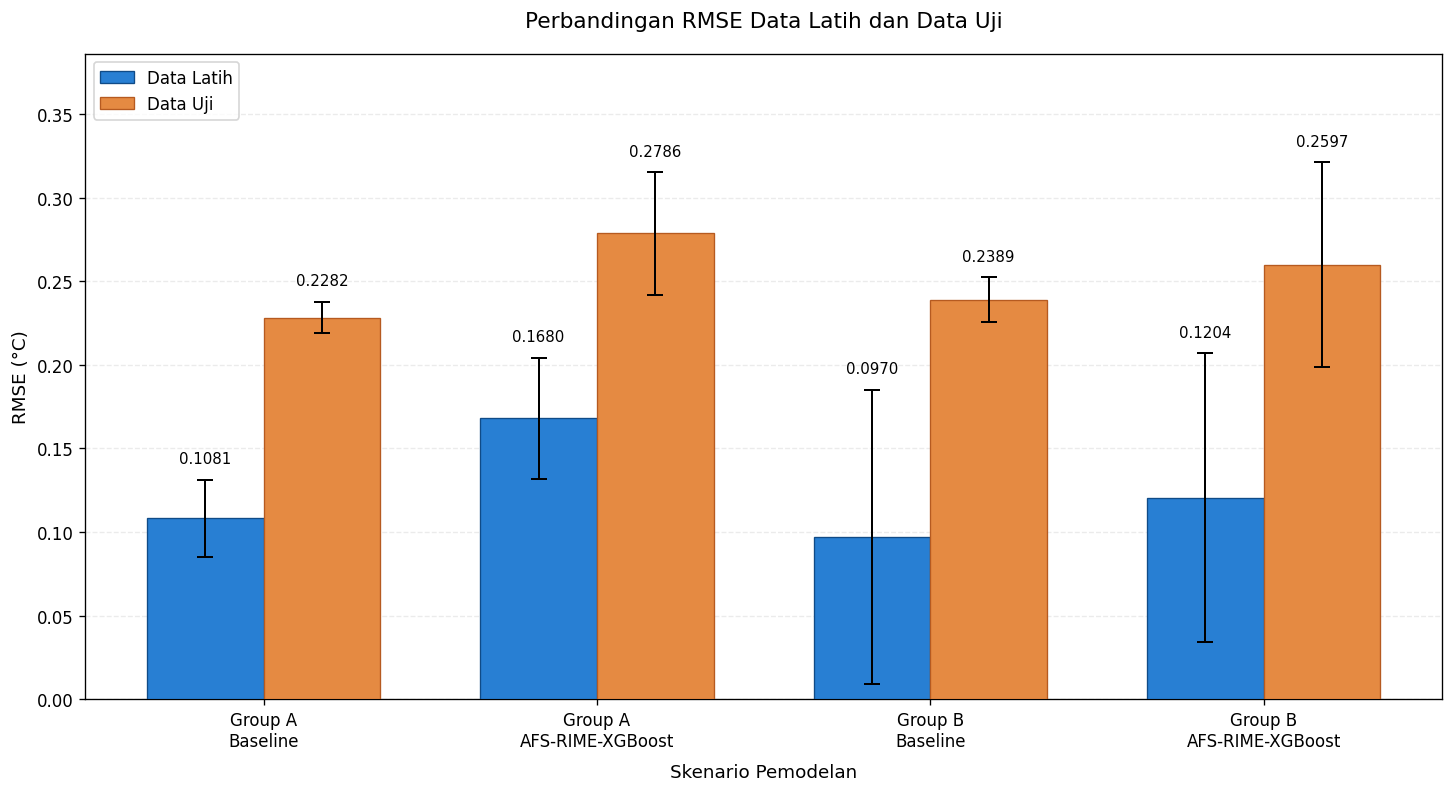


=== RINGKASAN RMSE ===


,Skenario,RMSE_Latih,Std_Latih,RMSE_Uji,Std_Uji
0,Group A\nBaseline,0.1081,0.0231,0.2282,0.0095
1,Group A\nAFS-RIME-XGBoost,0.1680,0.0362,0.2786,0.0367
2,Group B\nBaseline,0.0970,0.0881,0.2389,0.0135
3,Group B\nAFS-RIME-XGBoost,0.1204,0.0865,0.2597,0.0613



Grafik berhasil disimpan!
Lokasi: /content/drive/MyDrive/AFS_RIME_XGBoost/Hasil_BAB_IV


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
from pathlib import Path
from google.colab import drive

# ============================================================
# GRAFIK PERBANDINGAN RMSE DATA LATIH DAN DATA UJI
# BASELINE VS AFS-RIME-XGBOOST
# GROUP A DAN GROUP B - 20 PENGULANGAN
# ============================================================

# 1. HUBUNGKAN GOOGLE DRIVE
drive.mount("/content/drive")

BASE_DIR = Path("/content/drive/MyDrive/AFS_RIME_XGBoost")
SAVE_DIR = BASE_DIR / "Hasil_BAB_IV"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. MUAT HASIL EKSPERIMEN
# ============================================================

nama_variabel = [
    "cv_a_base",
    "cv_a_afs",
    "cv_b_base",
    "cv_b_afs"
]

if any(n not in globals() for n in nama_variabel):

    LOAD_PATH = BASE_DIR / "hasil_penelitian.pkl"

    if not LOAD_PATH.exists():
        raise FileNotFoundError(
            f"File tidak ditemukan: {LOAD_PATH}"
        )

    # Muat hanya file pickle yang dibuat sendiri/tepercaya
    with open(LOAD_PATH, "rb") as f:
        hasil = pickle.load(f)

    for nama in nama_variabel:
        if nama in hasil:
            globals()[nama] = hasil[nama]

missing = [n for n in nama_variabel if n not in globals()]

if missing:
    raise RuntimeError(
        f"Variabel belum tersedia: {missing}"
    )

# ============================================================
# 3. HITUNG MEAN DAN STANDAR DEVIASI RMSE
# ============================================================

def ringkasan_rmse(runs, nama):

    rmse_train = np.array([
        r["result"]["Train_RMSE"]
        for r in runs
    ], dtype=float)

    rmse_test = np.array([
        r["result"]["Test_RMSE"]
        for r in runs
    ], dtype=float)

    return {
        "Skenario": nama,
        "RMSE_Latih": rmse_train.mean(),
        "Std_Latih": rmse_train.std(ddof=1),
        "RMSE_Uji": rmse_test.mean(),
        "Std_Uji": rmse_test.std(ddof=1)
    }


data = [
    ringkasan_rmse(
        cv_a_base, "Group A\nBaseline"
    ),
    ringkasan_rmse(
        cv_a_afs, "Group A\nAFS-RIME-XGBoost"
    ),
    ringkasan_rmse(
        cv_b_base, "Group B\nBaseline"
    ),
    ringkasan_rmse(
        cv_b_afs, "Group B\nAFS-RIME-XGBoost"
    )
]

df_rmse = pd.DataFrame(data)

# ============================================================
# 4. PENGATURAN WARNA DAN TAMPILAN
# ============================================================

WARNA_LATIH = "#287FD3"
WARNA_UJI = "#E58A42"

TEPI_LATIH = "#104B87"
TEPI_UJI = "#B65A20"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "figure.dpi": 120
})

# ============================================================
# 5. MEMBUAT GROUPED BAR CHART
# ============================================================

x = np.arange(len(df_rmse))
lebar = 0.35

fig, ax = plt.subplots(
    figsize=(12, 6.5),
    constrained_layout=True
)

# RMSE DATA LATIH
bars_train = ax.bar(
    x - lebar / 2,
    df_rmse["RMSE_Latih"],
    width=lebar,
    yerr=df_rmse["Std_Latih"],
    color=WARNA_LATIH,
    edgecolor=TEPI_LATIH,
    linewidth=0.8,
    capsize=5,
    error_kw={
        "elinewidth": 1.2,
        "ecolor": "black",
        "capthick": 1.2
    },
    label="Data Latih",
    zorder=3
)

# RMSE DATA UJI
bars_test = ax.bar(
    x + lebar / 2,
    df_rmse["RMSE_Uji"],
    width=lebar,
    yerr=df_rmse["Std_Uji"],
    color=WARNA_UJI,
    edgecolor=TEPI_UJI,
    linewidth=0.8,
    capsize=5,
    error_kw={
        "elinewidth": 1.2,
        "ecolor": "black",
        "capthick": 1.2
    },
    label="Data Uji",
    zorder=3
)

# ============================================================
# 6. PENGATURAN SUMBU DAN LEGENDA
# ============================================================

ax.set_title(
    "Perbandingan RMSE Data Latih dan Data Uji",
    fontsize=13,
    pad=16
)

ax.set_xlabel(
    "Skenario Pemodelan",
    fontsize=11,
    labelpad=8
)

ax.set_ylabel(
    "RMSE (°C)",
    fontsize=11
)

ax.set_xticks(x)

ax.set_xticklabels(
    df_rmse["Skenario"],
    fontsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25,
    zorder=0
)

ax.set_axisbelow(True)

# Legenda dipindahkan ke kiri atas
ax.legend(
    loc="upper left",
    frameon=True,
    fontsize=10
)

# ============================================================
# 7. PERBAIKAN POSISI ANGKA
# DILETAKKAN DI ATAS UJUNG ERROR BAR
# ============================================================

# Mencari nilai tertinggi mean + standar deviasi
nilai_maks = max(
    (
        df_rmse["RMSE_Latih"]
        + df_rmse["Std_Latih"]
    ).max(),

    (
        df_rmse["RMSE_Uji"]
        + df_rmse["Std_Uji"]
    ).max()
)

# Menambahkan ruang untuk label angka
ax.set_ylim(
    0,
    nilai_maks + 0.065
)

# Jarak angka dari ujung error bar
jarak_label = 0.008

for i, row in df_rmse.iterrows():

    # ----------------------------------------
    # Label rata-rata RMSE data latih
    # ----------------------------------------

    posisi_x_latih = x[i] - lebar / 2

    posisi_y_latih = (
        row["RMSE_Latih"]
        + row["Std_Latih"]
        + jarak_label
    )

    ax.text(
        posisi_x_latih,
        posisi_y_latih,
        f'{row["RMSE_Latih"]:.4f}',
        ha="center",
        va="bottom",
        fontsize=9,
        color="black",
        zorder=5
    )

    # ----------------------------------------
    # Label rata-rata RMSE data uji
    # ----------------------------------------

    posisi_x_uji = x[i] + lebar / 2

    posisi_y_uji = (
        row["RMSE_Uji"]
        + row["Std_Uji"]
        + jarak_label
    )

    ax.text(
        posisi_x_uji,
        posisi_y_uji,
        f'{row["RMSE_Uji"]:.4f}',
        ha="center",
        va="bottom",
        fontsize=9,
        color="black",
        zorder=5
    )

# ============================================================
# 8. SIMPAN GRAFIK
# ============================================================

nama_file = "Grafik_Perbandingan_RMSE_Latih_Uji"

fig.savefig(
    SAVE_DIR / f"{nama_file}.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    SAVE_DIR / f"{nama_file}.pdf",
    bbox_inches="tight"
)

# Simpan data ringkasan
df_rmse.to_csv(
    SAVE_DIR / "Ringkasan_RMSE_Latih_Uji.csv",
    index=False
)

# ============================================================
# 9. TAMPILKAN HASIL
# ============================================================

plt.show()
plt.close(fig)

print("\n=== RINGKASAN RMSE ===")

display(
    df_rmse.round(4)
)

print("\nGrafik berhasil disimpan!")
print("Lokasi:", SAVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== PERUBAHAN KINERJA SETELAH AFS ===


,Kelompok,Perubahan_RMSE_%,Perubahan_MAE_%,Perubahan_R2
0,Group A,22.0903,24.9759,-0.0002
1,Group B,8.7226,9.8376,-0.0024


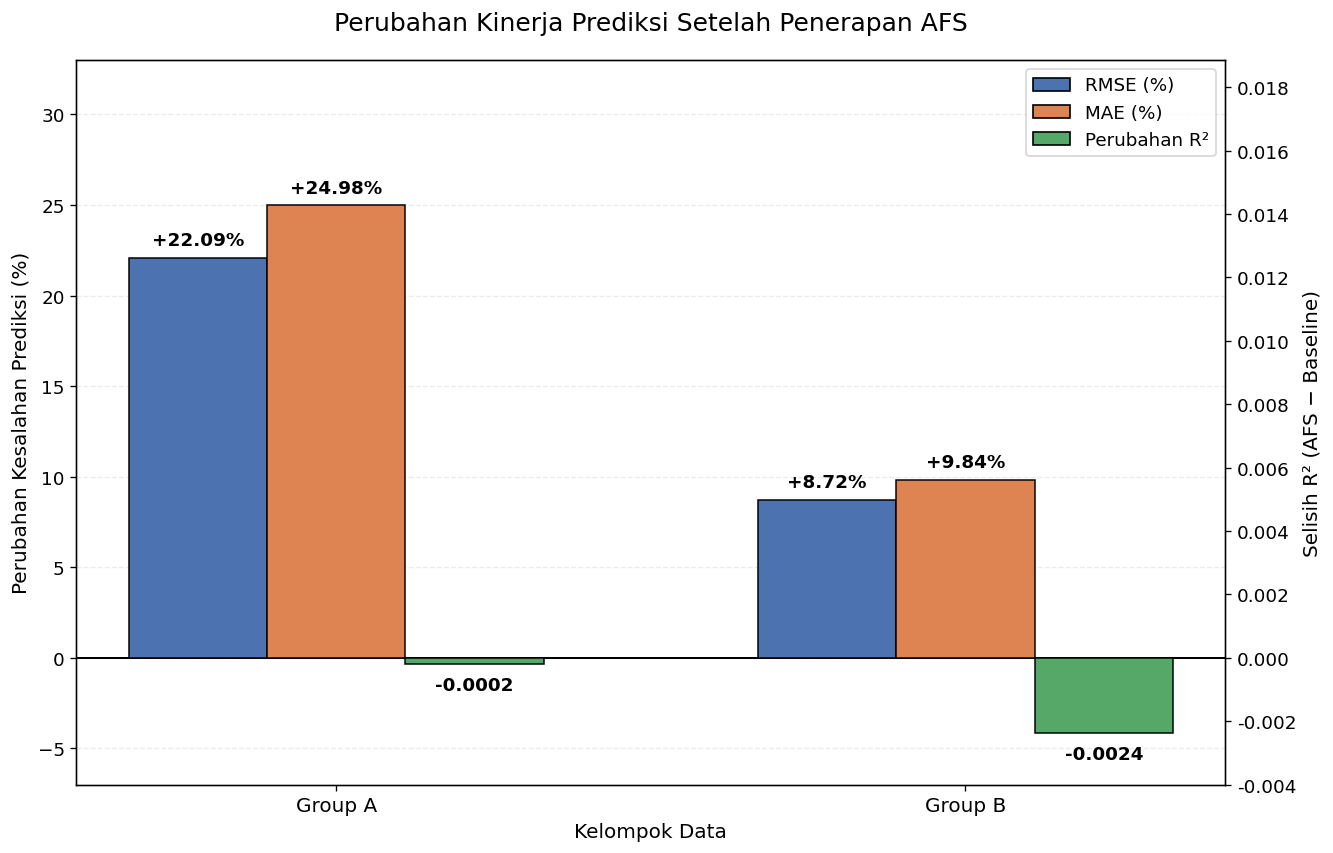


Grafik berhasil dibuat!
Batas bawah R²: -0.004
Batas atas R²: 0.01886
Lokasi: /content/drive/MyDrive/AFS_RIME_XGBoost/Hasil_BAB_IV


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
from pathlib import Path
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
from google.colab import drive

# ============================================================
# GAMBAR 4.6 - PERUBAHAN KINERJA PREDIKSI SETELAH AFS
# RMSE DAN MAE : PERSENTASE PERUBAHAN
# R2           : SELISIH ABSOLUT
# DATA         : TESTING SET, 20 PENGULANGAN
# ============================================================

# 1. HUBUNGKAN GOOGLE DRIVE
drive.mount("/content/drive")

BASE_DIR = Path("/content/drive/MyDrive/AFS_RIME_XGBoost")
SAVE_DIR = BASE_DIR / "Hasil_BAB_IV"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. MUAT HASIL EKSPERIMEN
# ============================================================

nama_variabel = [
    "cv_a_base", "cv_a_afs",
    "cv_b_base", "cv_b_afs"
]

if any(n not in globals() for n in nama_variabel):

    LOAD_PATH = BASE_DIR / "hasil_penelitian.pkl"

    if not LOAD_PATH.exists():
        raise FileNotFoundError(
            f"File tidak ditemukan: {LOAD_PATH}"
        )

    # Hanya muat file pickle milik sendiri/tepercaya
    with open(LOAD_PATH, "rb") as f:
        hasil = pickle.load(f)

    for nama in nama_variabel:
        if nama in hasil:
            globals()[nama] = hasil[nama]

missing = [n for n in nama_variabel if n not in globals()]

if missing:
    raise RuntimeError(
        f"Variabel belum tersedia: {missing}"
    )

# ============================================================
# 3. HITUNG PERUBAHAN KINERJA
# ============================================================

def mean_metrik(runs, nama_metrik):

    nilai = np.array([
        r["result"][nama_metrik]
        for r in runs
    ], dtype=float)

    if len(nilai) == 0 or not np.isfinite(nilai).all():
        raise ValueError(
            f"Data tidak valid: {nama_metrik}"
        )

    return nilai.mean()


def hitung_perubahan(base_runs, afs_runs, kelompok):

    rmse_base = mean_metrik(
        base_runs, "Test_RMSE"
    )
    rmse_afs = mean_metrik(
        afs_runs, "Test_RMSE"
    )

    mae_base = mean_metrik(
        base_runs, "Test_MAE"
    )
    mae_afs = mean_metrik(
        afs_runs, "Test_MAE"
    )

    r2_base = mean_metrik(
        base_runs, "Test_R2"
    )
    r2_afs = mean_metrik(
        afs_runs, "Test_R2"
    )

    return {
        "Kelompok": kelompok,

        "Perubahan_RMSE_%": (
            (rmse_afs - rmse_base) / rmse_base * 100
        ),

        "Perubahan_MAE_%": (
            (mae_afs - mae_base) / mae_base * 100
        ),

        "Perubahan_R2": r2_afs - r2_base
    }


df_perubahan = pd.DataFrame([
    hitung_perubahan(
        cv_a_base, cv_a_afs, "Group A"
    ),
    hitung_perubahan(
        cv_b_base, cv_b_afs, "Group B"
    )
])

print("=== PERUBAHAN KINERJA SETELAH AFS ===")
display(df_perubahan.round(4))

# ============================================================
# 4. PENGATURAN WARNA
# ============================================================

WARNA_RMSE = "#4C72B0"  # Biru
WARNA_MAE = "#DD8452"   # Oranye
WARNA_R2 = "#55A868"    # Hijau

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "legend.fontsize": 11,
    "figure.dpi": 120
})

# ============================================================
# 5. BUAT DIAGRAM BATANG
# ============================================================

x = np.arange(len(df_perubahan))
lebar = 0.22

fig, ax1 = plt.subplots(
    figsize=(11, 7),
    constrained_layout=True
)

# Sumbu Y kanan khusus selisih R2
ax2 = ax1.twinx()
ax2.patch.set_visible(False)

# RMSE
bars_rmse = ax1.bar(
    x - lebar,
    df_perubahan["Perubahan_RMSE_%"],
    width=lebar,
    color=WARNA_RMSE,
    edgecolor="black",
    linewidth=0.9,
    zorder=3
)

# MAE
bars_mae = ax1.bar(
    x,
    df_perubahan["Perubahan_MAE_%"],
    width=lebar,
    color=WARNA_MAE,
    edgecolor="black",
    linewidth=0.9,
    zorder=3
)

# Selisih R2
bars_r2 = ax2.bar(
    x + lebar,
    df_perubahan["Perubahan_R2"],
    width=lebar,
    color=WARNA_R2,
    edgecolor="black",
    linewidth=0.9,
    zorder=3
)

# ============================================================
# 6. PENGATURAN SUMBU DAN BATAS GRAFIK
# ============================================================

ax1.set_title(
    "Perubahan Kinerja Prediksi Setelah Penerapan AFS",
    pad=18
)

ax1.set_xlabel("Kelompok Data")

ax1.set_ylabel(
    "Perubahan Kesalahan Prediksi (%)"
)

ax2.set_ylabel(
    "Selisih R² (AFS − Baseline)"
)

ax1.set_xticks(x)
ax1.set_xticklabels(
    df_perubahan["Kelompok"],
    fontsize=12
)

# ------------------------------------------------------------
# BATAS SUMBU Y KIRI - RMSE DAN MAE
# ------------------------------------------------------------

persen_maks = max(
    df_perubahan["Perubahan_RMSE_%"].max(),
    df_perubahan["Perubahan_MAE_%"].max()
)

persen_min = min(
    0,
    df_perubahan["Perubahan_RMSE_%"].min(),
    df_perubahan["Perubahan_MAE_%"].min()
)

bawah_kiri = min(
    -7.0,
    persen_min - 2
)

atas_kiri = max(
    33.0,
    persen_maks + 7
)

ax1.set_ylim(
    bawah_kiri,
    atas_kiri
)

# ------------------------------------------------------------
# BATAS SUMBU Y KANAN - R2
# REVISI: BATAS BAWAH MENJADI -0.004
# ------------------------------------------------------------

bawah_kanan = -0.004

# Pastikan seluruh nilai R2 masih berada dalam rentang
if df_perubahan["Perubahan_R2"].min() < bawah_kanan:
    raise ValueError(
        "Ada selisih R2 di bawah -0.004. "
        "Perbesar batas bawah sumbu kanan."
    )

# Menyesuaikan batas atas agar garis nol kedua
# sumbu Y tetap berada pada posisi yang sama
atas_kanan = (
    (-bawah_kanan)
    * atas_kiri
    / (-bawah_kiri)
)

ax2.set_ylim(
    bawah_kanan,
    atas_kanan
)

# Interval angka sumbu kanan
ax2.yaxis.set_major_locator(
    MultipleLocator(0.002)
)

ax2.yaxis.set_major_formatter(
    FormatStrFormatter("%.3f")
)

# Garis horizontal nol
ax1.axhline(
    0,
    color="black",
    linewidth=1.2,
    zorder=2
)

# Grid
ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax1.set_axisbelow(True)

# ============================================================
# 7. LEGENDA POJOK KANAN ATAS
# ============================================================

legend_elements = [
    Patch(
        facecolor=WARNA_RMSE,
        edgecolor="black",
        label="RMSE (%)"
    ),
    Patch(
        facecolor=WARNA_MAE,
        edgecolor="black",
        label="MAE (%)"
    ),
    Patch(
        facecolor=WARNA_R2,
        edgecolor="black",
        label="Perubahan R²"
    )
]

ax1.legend(
    handles=legend_elements,
    loc="upper right",
    frameon=True
)

# ============================================================
# 8. TAMBAHKAN NILAI DI ATAS / BAWAH BATANG
# ============================================================

def label_persen(ax, bars):

    for bar in bars:

        tinggi = bar.get_height()
        posisi_x = (
            bar.get_x() + bar.get_width() / 2
        )

        offset = 5 if tinggi >= 0 else -5
        posisi = "bottom" if tinggi >= 0 else "top"

        ax.annotate(
            f"{tinggi:+.2f}%",
            xy=(posisi_x, tinggi),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            va=posisi,
            fontsize=11,
            fontweight="bold",
            clip_on=False
        )


label_persen(ax1, bars_rmse)
label_persen(ax1, bars_mae)

# Label nilai R2
for bar in bars_r2:

    tinggi = bar.get_height()
    posisi_x = (
        bar.get_x() + bar.get_width() / 2
    )

    offset = 5 if tinggi >= 0 else -7
    posisi = "bottom" if tinggi >= 0 else "top"

    ax2.annotate(
        f"{tinggi:+.4f}",
        xy=(posisi_x, tinggi),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        va=posisi,
        fontsize=11,
        fontweight="bold",
        clip_on=False
    )

# ============================================================
# 9. SIMPAN GRAFIK DAN DATA
# ============================================================

nama_file = "Gambar_4_6_Perubahan_Kinerja_Prediksi_AFS"

fig.savefig(
    SAVE_DIR / f"{nama_file}.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    SAVE_DIR / f"{nama_file}.pdf",
    bbox_inches="tight"
)

df_perubahan.to_csv(
    SAVE_DIR / "Data_Perubahan_Kinerja_Prediksi_AFS.csv",
    index=False
)

# ============================================================
# 10. TAMPILKAN HASIL
# ============================================================

plt.show()
plt.close(fig)

print("\nGrafik berhasil dibuat!")
print("Batas bawah R²:", bawah_kanan)
print("Batas atas R²:", round(atas_kanan, 5))
print("Lokasi:", SAVE_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== TABEL PERSENTASE PERUBAHAN SETELAH AFS ===


,Kelompok,Reduksi_Fitur_%,Pengurangan_Waktu_Eksekusi_%,Pengurangan_Waktu_Inferensi_%
0,Group A,87.73,60.08,-11.73
1,Group B,62.88,3.92,5.55


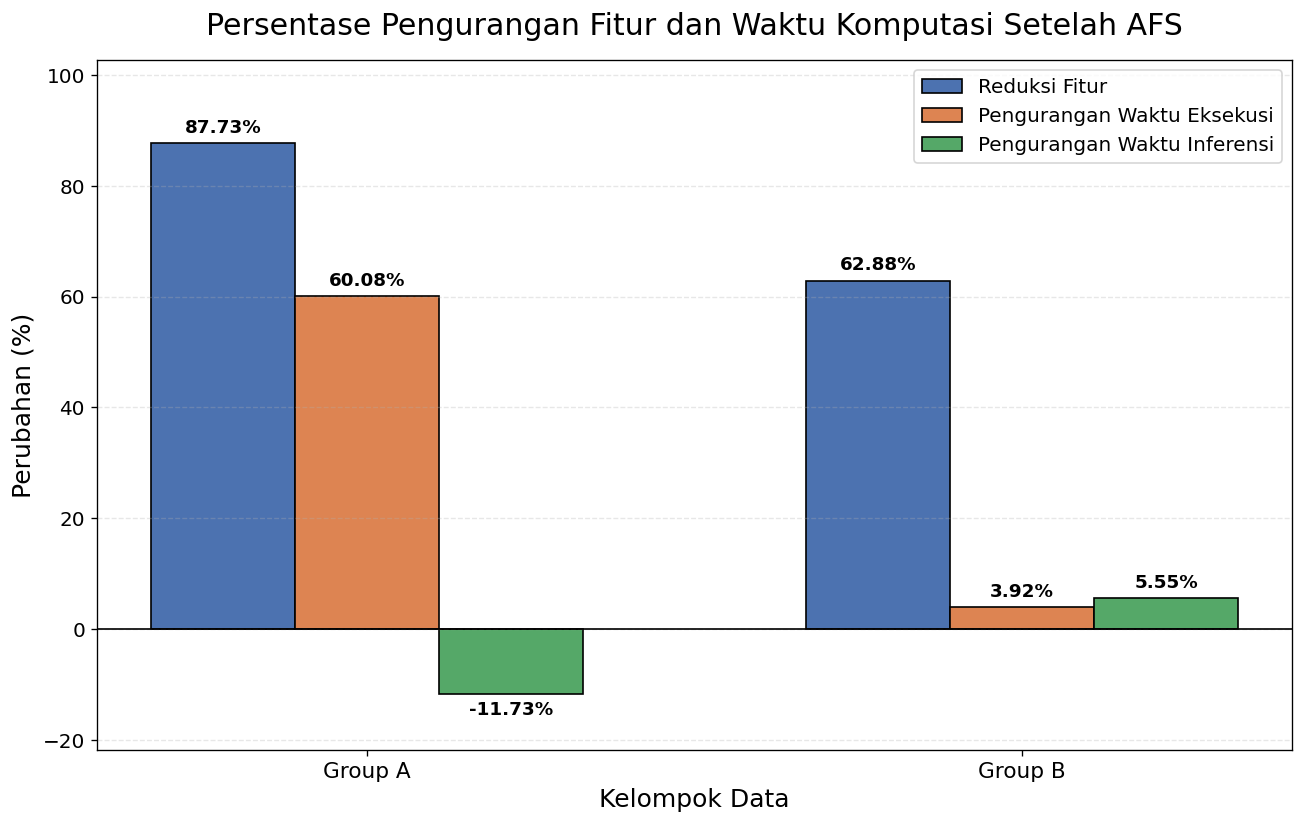


✅ Grafik berhasil dibuat dan disimpan di:
/content/drive/MyDrive/AFS_RIME_XGBoost/Hasil_BAB_IV


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

# ============================================================
# 1. HUBUNGKAN GOOGLE DRIVE
# ============================================================
drive.mount('/content/drive')

SAVE_DIR = Path('/content/drive/MyDrive/AFS_RIME_XGBoost/Hasil_BAB_IV')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. DATA RATA-RATA HASIL EKSPERIMEN
#    (diambil dari ringkasan hasil yang sudah final)
# ============================================================
data_ringkas = pd.DataFrame({
    "Kelompok": ["Group A", "Group B"],
    "Fitur_Baseline": [33.0, 33.0],
    "Fitur_AFS": [4.05, 12.25],
    "Waktu_Eksekusi_Baseline": [587.7282, 103.1199],
    "Waktu_Eksekusi_AFS": [234.6270, 99.0820],
    "Waktu_Inferensi_Baseline": [10.2391, 1.7049],
    "Waktu_Inferensi_AFS": [11.4401, 1.6103]
})

# ============================================================
# 3. HITUNG PERSENTASE PERUBAHAN
#    Rumus:
#    ((Baseline - AFS) / Baseline) * 100
#    Nilai positif  = pengurangan
#    Nilai negatif  = peningkatan
# ============================================================
data_ringkas["Reduksi_Fitur_%"] = (
    (data_ringkas["Fitur_Baseline"] - data_ringkas["Fitur_AFS"])
    / data_ringkas["Fitur_Baseline"] * 100
)

data_ringkas["Pengurangan_Waktu_Eksekusi_%"] = (
    (data_ringkas["Waktu_Eksekusi_Baseline"] - data_ringkas["Waktu_Eksekusi_AFS"])
    / data_ringkas["Waktu_Eksekusi_Baseline"] * 100
)

data_ringkas["Pengurangan_Waktu_Inferensi_%"] = (
    (data_ringkas["Waktu_Inferensi_Baseline"] - data_ringkas["Waktu_Inferensi_AFS"])
    / data_ringkas["Waktu_Inferensi_Baseline"] * 100
)

# ============================================================
# 4. TAMPILKAN TABEL HASIL
# ============================================================
tabel_49 = data_ringkas[[
    "Kelompok",
    "Reduksi_Fitur_%",
    "Pengurangan_Waktu_Eksekusi_%",
    "Pengurangan_Waktu_Inferensi_%"
]].copy()

print("=== TABEL PERSENTASE PERUBAHAN SETELAH AFS ===")
display(tabel_49.round(2))

# Simpan tabel
tabel_49.to_csv(SAVE_DIR / "Tabel_4_9_Persentase_Pengurangan_AFS.csv", index=False)

# ============================================================
# 5. SIAPKAN DATA GRAFIK
# ============================================================
kelompok = data_ringkas["Kelompok"].tolist()
reduksi_fitur = data_ringkas["Reduksi_Fitur_%"].values
reduksi_eksekusi = data_ringkas["Pengurangan_Waktu_Eksekusi_%"].values
reduksi_inferensi = data_ringkas["Pengurangan_Waktu_Inferensi_%"].values

x = np.arange(len(kelompok))
width = 0.22

# ============================================================
# 6. BUAT GRAFIK BATANG
# ============================================================
fig, ax = plt.subplots(figsize=(11, 7))

bars1 = ax.bar(
    x - width,
    reduksi_fitur,
    width,
    label="Reduksi Fitur",
    color="#4C72B0",
    edgecolor="black"
)

bars2 = ax.bar(
    x,
    reduksi_eksekusi,
    width,
    label="Pengurangan Waktu Eksekusi",
    color="#DD8452",
    edgecolor="black"
)

bars3 = ax.bar(
    x + width,
    reduksi_inferensi,
    width,
    label="Pengurangan Waktu Inferensi",
    color="#55A868",
    edgecolor="black"
)

# Garis nol
ax.axhline(0, color="black", linewidth=1)

# ============================================================
# 7. FORMAT AXIS, JUDUL, LABEL
# ============================================================
ax.set_title("Persentase Pengurangan Fitur dan Waktu Komputasi Setelah AFS", fontsize=18, pad=15)
ax.set_xlabel("Kelompok Data", fontsize=15)
ax.set_ylabel("Perubahan (%)", fontsize=15)
ax.set_xticks(x)
ax.set_xticklabels(kelompok, fontsize=13)
ax.tick_params(axis='y', labelsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(loc="upper right", fontsize=12)

# Batas sumbu y otomatis, tapi diberi ruang untuk label
nilai_min = min(reduksi_fitur.min(), reduksi_eksekusi.min(), reduksi_inferensi.min())
nilai_max = max(reduksi_fitur.max(), reduksi_eksekusi.max(), reduksi_inferensi.max())
ax.set_ylim(nilai_min - 10, nilai_max + 15)

# ============================================================
# 8. TAMBAHKAN LABEL NILAI DI ATAS / BAWAH BATANG
# ============================================================
def tambah_label(bars):
    for bar in bars:
        tinggi = bar.get_height()
        x_pos = bar.get_x() + bar.get_width() / 2

        if tinggi >= 0:
            ax.text(
                x_pos,
                tinggi + 1.2,
                f"{tinggi:.2f}%",
                ha="center",
                va="bottom",
                fontsize=11,
                fontweight="bold"
            )
        else:
            ax.text(
                x_pos,
                tinggi - 1.2,
                f"{tinggi:.2f}%",
                ha="center",
                va="top",
                fontsize=11,
                fontweight="bold"
            )

tambah_label(bars1)
tambah_label(bars2)
tambah_label(bars3)

plt.tight_layout()

# ============================================================
# 9. SIMPAN GRAFIK
# ============================================================
fig.savefig(SAVE_DIR / "Gambar_4_7_Pengurangan_Fitur_dan_Waktu_AFS.png", dpi=300, bbox_inches="tight")
fig.savefig(SAVE_DIR / "Gambar_4_7_Pengurangan_Fitur_dan_Waktu_AFS.pdf", bbox_inches="tight")

plt.show()

print("\n✅ Grafik berhasil dibuat dan disimpan di:")
print(SAVE_DIR)

In [ ]:

import numpy as np
import pandas as pd
import pickle
from pathlib import Path
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
from google.colab import drive

# ============================================================
# UJI WILCOXON SIGNED-RANK BERPASANGAN
# BASELINE VS AFS-RIME-XGBOOST
# METRIK UTAMA : RMSE DATA UJI
# ============================================================

drive.mount("/content/drive")

BASE_DIR = Path("/content/drive/MyDrive/AFS_RIME_XGBoost")
SAVE_DIR = BASE_DIR / "Hasil_BAB_IV"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

nama_variabel = [
    "cv_a_base", "cv_a_afs",
    "cv_b_base", "cv_b_afs"
]

if any(n not in globals() for n in nama_variabel):
    with open(BASE_DIR / "hasil_penelitian.pkl", "rb") as f:
        hasil = pickle.load(f)  # Hanya dari file tepercaya

    for nama in nama_variabel:
        globals()[nama] = hasil[nama]

# ============================================================
# FUNGSI PENGUJIAN
# ============================================================

def uji_wilcoxon(base_runs, afs_runs, kelompok):

    base = {
        int(r["result"]["Seed"]): r["result"]["Test_RMSE"]
        for r in base_runs
    }

    afs = {
        int(r["result"]["Seed"]): r["result"]["Test_RMSE"]
        for r in afs_runs
    }

    seeds = sorted(set(base) & set(afs))

    if len(seeds) != 20:
        raise ValueError(
            f"{kelompok}: ditemukan {len(seeds)} seed bersama, "
            "seharusnya 20."
        )

    rmse_base = np.array(
        [base[s] for s in seeds], dtype=float
    )
    rmse_afs = np.array(
        [afs[s] for s in seeds], dtype=float
    )

    selisih = rmse_afs - rmse_base

    # Uji dua arah
    if np.allclose(selisih, 0, atol=0, rtol=0):
        statistik, p_value = 0.0, 1.0
    else:
        statistik, p_value = wilcoxon(
            selisih,
            alternative="two-sided",
            zero_method="wilcox",
            method="auto"
        )

    return {
        "Kelompok": kelompok,
        "N": len(seeds),
        "Mean_Selisih_RMSE": np.mean(selisih),
        "Median_Selisih_RMSE": np.median(selisih),
        "Statistik_W": statistik,
        "P_Value": p_value
    }, pd.DataFrame({
        "Kelompok": kelompok,
        "Seed": seeds,
        "RMSE_Baseline": rmse_base,
        "RMSE_AFS": rmse_afs,
        "Selisih_RMSE": selisih
    })

# ============================================================
# PENGUJIAN GROUP A DAN GROUP B
# ============================================================

hasil_a, selisih_a = uji_wilcoxon(
    cv_a_base, cv_a_afs, "Group A"
)

hasil_b, selisih_b = uji_wilcoxon(
    cv_b_base, cv_b_afs, "Group B"
)

df_stat = pd.DataFrame([hasil_a, hasil_b])

# Koreksi Holm untuk dua pengujian
df_stat["P_Holm"] = multipletests(
    df_stat["P_Value"],
    alpha=0.05,
    method="holm"
)[1]

df_stat["Kesimpulan"] = np.where(
    df_stat["P_Holm"] <= 0.05,
    "Signifikan",
    "Tidak signifikan"
)

# ============================================================
# TAMPILKAN DAN SIMPAN HASIL
# ============================================================

print("=== HASIL UJI WILCOXON ===")
display(df_stat.round(6))

df_stat.to_csv(
    SAVE_DIR / "Hasil_Uji_Wilcoxon_RMSE.csv",
    index=False
)

pd.concat(
    [selisih_a, selisih_b],
    ignore_index=True
).to_csv(
    SAVE_DIR / "Data_Selisih_RMSE_Berpasangan.csv",
    index=False
)

print("Hasil pengujian tersimpan di:", SAVE_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== HASIL UJI WILCOXON ===


,Kelompok,N,Mean_Selisih_RMSE,Median_Selisih_RMSE,Statistik_W,P_Value,P_Holm,Kesimpulan
0,Group A,20,0.050404,0.052509,3.0,0.000010,0.000019,Signifikan
1,Group B,20,0.020836,0.008314,78.0,0.329983,0.329983,Tidak signifikan


Hasil pengujian tersimpan di: /content/drive/MyDrive/AFS_RIME_XGBoost/Hasil_BAB_IV


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

for name, data, runs, test_size in [
    ("Group A", df_group_a, cv_a_base, 0.30),
    ("Group B", df_group_b, cv_b_base, 0.20)
]:
    y = data[TARGET].to_numpy()

    _, test_42 = train_test_split(
        y, test_size=test_size, random_state=42
    )

    _, test_43 = train_test_split(
        y, test_size=test_size, random_state=43
    )

    actual = runs[1]["y_test"]  # Run kedua, seed eksperimen 43

    print(f"\n{name}")
    print("Sesuai pembagian seed 42:", np.array_equal(actual, test_42))
    print("Sesuai pembagian seed 43:", np.array_equal(actual, test_43))


Group A
Sesuai pembagian seed 42: True
Sesuai pembagian seed 43: False

Group B
Sesuai pembagian seed 42: True
Sesuai pembagian seed 43: False


In [ ]:

import pandas as pd
import numpy as np
from itertools import combinations

def buat_tabel_lampiran(runs, afs=False):
    rows = []

    for i, run in enumerate(runs, start=1):
        r = run["result"]
        fitur = list(r["Selected_Features_List"])

        assert len(fitur) == r["N_Fitur"], (
            f"Run {i}: jumlah fitur tidak sesuai."
        )

        row = {
            "Run": i,
            "Seed": r["Seed"],
            "Jumlah Fitur": r["N_Fitur"],
            "MAE (°C)": r["Test_MAE"],
            "RMSE (°C)": r["Test_RMSE"],
            "R²": r["Test_R2"],
            "Waktu Pemodelan (s)": r["Train_Time"]
        }

        if afs:
            row["Variabel Terpilih"] = ", ".join(fitur)

        rows.append(row)

    df = pd.DataFrame(rows)

    if afs:
        cols = [
            "Run", "Seed", "Variabel Terpilih",
            "Jumlah Fitur", "MAE (°C)", "RMSE (°C)",
            "R²", "Waktu Pemodelan (s)"
        ]
        df = df[cols]

    return df


# Menyiapkan keempat tabel
tabel = {
    "A_Baseline": buat_tabel_lampiran(cv_a_base),
    "A_AFS": buat_tabel_lampiran(cv_a_afs, afs=True),
    "B_Baseline": buat_tabel_lampiran(cv_b_base),
    "B_AFS": buat_tabel_lampiran(cv_b_afs, afs=True)
}

# Memastikan kelengkapan run dan pasangan seed
for nama, df in tabel.items():
    assert len(df) == 20, f"{nama}: jumlah run bukan 20."
    assert df["Seed"].tolist() == list(range(42, 62)), (
        f"{nama}: urutan seed tidak sesuai."
    )

for grup in ["A", "B"]:
    assert (
        tabel[f"{grup}_Baseline"]["Seed"].tolist()
        == tabel[f"{grup}_AFS"]["Seed"].tolist()
    )

print("=== VERIFIKASI LAMPIRAN ===")

for nama, df in tabel.items():
    print(f"\n{nama}")
    print("Jumlah run:", len(df))
    print("Rata-rata MAE:", round(df["MAE (°C)"].mean(), 4))
    print("Rata-rata RMSE:", round(df["RMSE (°C)"].mean(), 4))
    print("Rata-rata R²:", round(df["R²"].mean(), 4))
    print(
        "Rata-rata waktu:",
        round(df["Waktu Pemodelan (s)"].mean(), 4)
    )

# Memeriksa statistik subset fitur
for grup, runs in [("A", cv_a_afs), ("B", cv_b_afs)]:
    subsets = [
        set(run["result"]["Selected_Features_List"])
        for run in runs
    ]

    nilai_jaccard = [
        len(a & b) / len(a | b)
        for a, b in combinations(subsets, 2)
    ]

    jumlah = [len(s) for s in subsets]

    print(f"\n=== GROUP {grup}: SUBSET FITUR ===")
    print("Jumlah fitur minimum:", min(jumlah))
    print("Jumlah fitur maksimum:", max(jumlah))
    print("Rata-rata jumlah fitur:", np.mean(jumlah))
    print(
        "Subset unik:",
        len({frozenset(s) for s in subsets})
    )
    print("Jumlah pasangan:", len(nilai_jaccard))
    print(
        "Rata-rata Jaccard presisi penuh:",
        f"{np.mean(nilai_jaccard):.8f}"
    )
    print(
        "Rata-rata Jaccard 3 desimal:",
        f"{np.mean(nilai_jaccard):.3f}"
    )

# Menyimpan seluruh tabel untuk keperluan lampiran
with pd.ExcelWriter("Lampiran_Hasil_20_Run.xlsx") as writer:
    for nama, df in tabel.items():
        df.to_excel(writer, sheet_name=nama, index=False)

print("\nFile Lampiran_Hasil_20_Run.xlsx berhasil dibuat.")


=== VERIFIKASI LAMPIRAN ===

A_Baseline
Jumlah run: 20
Rata-rata MAE: 0.1442
Rata-rata RMSE: 0.2282
Rata-rata R²: 0.9996
Rata-rata waktu: 587.7282

A_AFS
Jumlah run: 20
Rata-rata MAE: 0.1802
Rata-rata RMSE: 0.2786
Rata-rata R²: 0.9994
Rata-rata waktu: 234.627

B_Baseline
Jumlah run: 20
Rata-rata MAE: 0.1595
Rata-rata RMSE: 0.2389
Rata-rata R²: 0.9901
Rata-rata waktu: 103.1199

B_AFS
Jumlah run: 20
Rata-rata MAE: 0.1752
Rata-rata RMSE: 0.2597
Rata-rata R²: 0.9877
Rata-rata waktu: 99.082

=== GROUP A: SUBSET FITUR ===
Jumlah fitur minimum: 3
Jumlah fitur maksimum: 8
Rata-rata jumlah fitur: 4.05
Subset unik: 20
Jumlah pasangan: 190
Rata-rata Jaccard presisi penuh: 0.22375452
Rata-rata Jaccard 3 desimal: 0.224

=== GROUP B: SUBSET FITUR ===
Jumlah fitur minimum: 6
Jumlah fitur maksimum: 20
Rata-rata jumlah fitur: 12.25
Subset unik: 20
Jumlah pasangan: 190
Rata-rata Jaccard presisi penuh: 0.27049654
Rata-rata Jaccard 3 desimal: 0.270

File Lampiran_Hasil_20_Run.xlsx berhasil dibuat.


In [ ]:

import sys
import psutil
import pandas as pd
import sklearn
import xgboost

print("Python:", sys.version.split()[0])
print("XGBoost:", xgboost.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)
print("RAM:", round(psutil.virtual_memory().total / (1024**3), 2), "GB")

# Informasi prosesor
!lscpu | grep "Model name"


Python: 3.13.18
XGBoost: 3.4.1
Scikit-learn: 1.6.1
Pandas: 2.2.3
RAM: 12.67 GB
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz


Kunci hasil eksperimen:
dict_keys(['AFS', 'Seed', 'N_Fitur', 'Selected_Features_List', 'AFS_Time', 'RIME_Time', 'Fit_Time', 'Train_Time', 'Infer_Time_ms', 'Test_MAE', 'Test_RMSE', 'Test_MBE', 'Test_R2', 'Train_MAE', 'Train_RMSE', 'Train_MBE', 'Train_R2', 'best_hp'])

=== Group A ===
 Seed  RMSE_Baseline  RMSE_AFS  Selisih_RMSE
   42       0.235467  0.226098     -0.009369
   43       0.240748  0.301684      0.060936
   44       0.218704  0.297746      0.079042
   45       0.219442  0.286064      0.066622
   46       0.220980  0.278745      0.057765
   47       0.235102  0.357327      0.122225
   48       0.246386  0.246223     -0.000163
   49       0.234016  0.289343      0.055327
   50       0.228048  0.339628      0.111580
   51       0.225225  0.240115      0.014890
   52       0.210370  0.260061      0.049691
   53       0.224829  0.308719      0.083890
   54       0.227373  0.253968      0.026596
   55       0.227034  0.246688      0.019654
   56       0.217550  0.288151      0.070

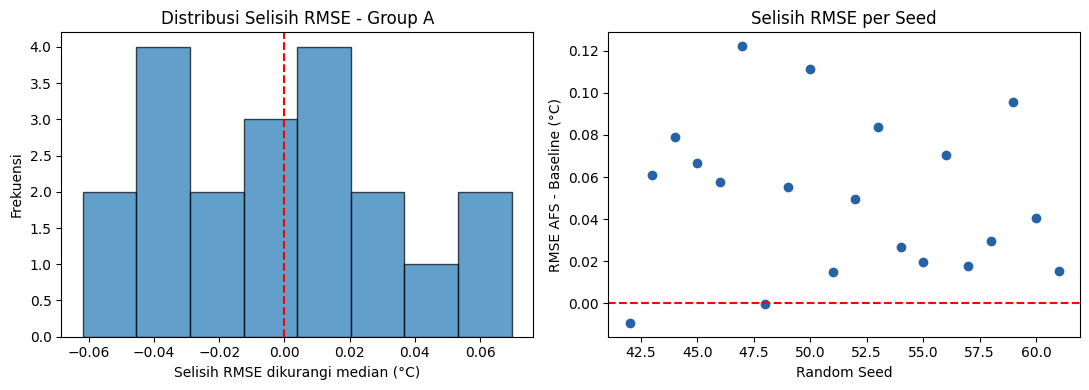


=== Group B ===
 Seed  RMSE_Baseline  RMSE_AFS  Selisih_RMSE
   42       0.233385  0.242967      0.009582
   43       0.237574  0.192654     -0.044920
   44       0.278005  0.225231     -0.052774
   45       0.238558  0.238343     -0.000215
   46       0.226329  0.205614     -0.020714
   47       0.225385  0.336871      0.111486
   48       0.239454  0.213172     -0.026282
   49       0.232969  0.300539      0.067570
   50       0.240114  0.265991      0.025877
   51       0.230606  0.260200      0.029594
   52       0.237351  0.276904      0.039553
   53       0.254312  0.241203     -0.013109
   54       0.230109  0.237156      0.007047
   55       0.236694  0.210457     -0.026237
   56       0.235311  0.314949      0.079638
   57       0.252865  0.245409     -0.007456
   58       0.253535  0.469782      0.216247
   59       0.222198  0.238624      0.016426
   60       0.221875  0.240225      0.018350
   61       0.250847  0.237901     -0.012947

Rata-rata selisih : 0.020836
Median s

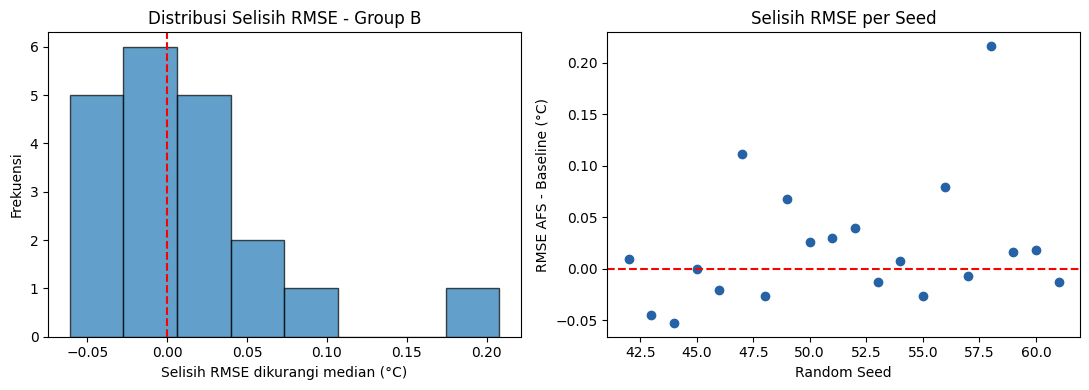

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew, binomtest

# Periksa terlebih dahulu nama kolom RMSE uji
print("Kunci hasil eksperimen:")
print(cv_b_base[0]["result"].keys())

def extract_rmse_test(runs):
    records = []

    for run in runs:
        result = run["result"]

        # Mendeteksi nama kolom RMSE data uji
        candidates = [
            key for key in result.keys()
            if "rmse" in key.lower()
            and ("test" in key.lower() or "uji" in key.lower())
        ]

        if len(candidates) != 1:
            raise KeyError(
                f"Kolom RMSE uji belum teridentifikasi. "
                f"Kolom tersedia: {list(result.keys())}"
            )

        records.append({
            "Seed": int(result["Seed"]),
            "RMSE": float(result[candidates[0]])
        })

    df = pd.DataFrame(records)

    if df["Seed"].duplicated().any():
        raise ValueError("Terdapat seed yang berulang.")

    return df


def check_paired_difference(group, baseline, afs):
    df_base = extract_rmse_test(baseline)
    df_afs = extract_rmse_test(afs)

    paired = df_base.merge(
        df_afs,
        on="Seed",
        how="inner",
        suffixes=("_Baseline", "_AFS"),
        validate="one_to_one"
    ).sort_values("Seed")

    if len(paired) != 20:
        raise ValueError(
            f"{group}: pasangan lengkap hanya {len(paired)}."
        )

    paired["Selisih_RMSE"] = (
        paired["RMSE_AFS"] -
        paired["RMSE_Baseline"]
    )

    d = paired["Selisih_RMSE"].to_numpy()

    print(f"\n=== {group} ===")
    print(paired.to_string(index=False))

    print(f"\nRata-rata selisih : {np.mean(d):.6f}")
    print(f"Median selisih    : {np.median(d):.6f}")
    print(f"Skewness          : {skew(d, bias=False):.4f}")
    print(f"Selisih positif   : {np.sum(d > 0)}")
    print(f"Selisih negatif   : {np.sum(d < 0)}")
    print(f"Selisih nol       : {np.sum(d == 0)}")

    # Uji tanda sebagai pemeriksaan tambahan
    n_nonzero = np.sum(d != 0)

    if n_nonzero > 0:
        p_sign = binomtest(
            np.sum(d > 0),
            n=n_nonzero,
            p=0.5,
            alternative="two-sided"
        ).pvalue

        print(f"p-value uji tanda : {p_sign:.6f}")

    # Visualisasi distribusi selisih
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].hist(
        d - np.median(d),
        bins=8,
        edgecolor="black",
        alpha=0.7
    )
    axes[0].axvline(0, color="red", linestyle="--")
    axes[0].set_title(f"Distribusi Selisih RMSE - {group}")
    axes[0].set_xlabel("Selisih RMSE dikurangi median (°C)")
    axes[0].set_ylabel("Frekuensi")

    axes[1].scatter(
        paired["Seed"],
        d,
        color="#2563A6"
    )
    axes[1].axhline(0, color="red", linestyle="--")
    axes[1].set_title("Selisih RMSE per Seed")
    axes[1].set_xlabel("Random Seed")
    axes[1].set_ylabel("RMSE AFS - Baseline (°C)")

    plt.tight_layout()
    plt.show()

    return paired


# Periksa kedua kelompok
paired_a = check_paired_difference(
    "Group A", cv_a_base, cv_a_afs
)

paired_b = check_paired_difference(
    "Group B", cv_b_base, cv_b_afs
)


In [5]:
"""
Ekspor lampiran AFS-RIME-XGBoost dari hasil eksperimen yang sudah ada di memori.
Jalankan setelah cv_a_base, cv_a_afs, cv_b_base, cv_b_afs terbentuk.
Di Google Colab dapat menggunakan: %run -i script_lampiran_afs_rime.py
"""
import ast
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd

# ============================================================
# 1. KONFIGURASI
# ============================================================
N_RUNS = 20
N_ITERATIONS = 20
OUTPUT = (Path('/content') if Path('/content').exists() else Path.cwd()) / 'Lampiran_Optimasi_AFS_RIME_XGBoost.xlsx'

# Isi dengan daftar lengkap 33 nama fitur bila ingin fitur yang tidak
# pernah terpilih tetap tampil dengan frekuensi nol. Contoh:
# ALL_FEATURE_NAMES = list(nama_dataframe_33_fitur.columns)
ALL_FEATURE_NAMES = None

SCENARIOS = {
    'A_Baseline': cv_a_base,
    'A_AFS': cv_a_afs,
    'B_Baseline': cv_b_base,
    'B_AFS': cv_b_afs,
}
AFS_SCENARIOS = {'A': cv_a_afs, 'B': cv_b_afs}
HP_NAMES = ['n_estimators', 'max_depth', 'learning_rate',
            'min_child_weight', 'reg_lambda']

# ============================================================
# 2. FUNGSI PEMBANTU DAN VALIDASI
# ============================================================
def sort_runs(runs, scenario):
    if len(runs) != N_RUNS:
        raise ValueError(f'{scenario}: ada {len(runs)} run, seharusnya {N_RUNS}.')
    if any('result' not in run or 'Seed' not in run['result'] for run in runs):
        raise KeyError(f'{scenario}: result.Seed harus tersedia pada setiap run.')
    sorted_runs = sorted(runs, key=lambda r: int(r['result']['Seed']))
    seeds = [int(r['result']['Seed']) for r in sorted_runs]
    if len(set(seeds)) != N_RUNS:
        raise ValueError(f'{scenario}: ditemukan seed duplikat.')
    return sorted_runs


def parse_features(raw):
    if isinstance(raw, str):
        try:
            raw = ast.literal_eval(raw)
        except (ValueError, SyntaxError) as exc:
            raise ValueError('Selected_Features_List bukan list yang dapat dibaca.') from exc
    if isinstance(raw, np.ndarray):
        raw = raw.tolist()
    if not isinstance(raw, (list, tuple, set)):
        raise TypeError('Selected_Features_List harus list, tuple, atau set.')
    selected = [str(item) for item in raw]
    if len(selected) != len(set(selected)):
        raise ValueError('Nama fitur yang sama muncul dua kali dalam satu subset.')
    return set(selected)


def convergence_sheet(runs, scenario, key, std_ddof):
    runs = sort_runs(runs, scenario)
    seeds = [int(r['result']['Seed']) for r in runs]
    cols = []
    for run in runs:
        if key not in run:
            raise KeyError(f'{scenario}: {key} tidak ditemukan.')
        values = np.asarray(run[key], dtype=float).ravel()
        if len(values) != N_ITERATIONS or not np.all(np.isfinite(values)):
            raise ValueError(f'{scenario}: panjang/nilai {key} tidak valid.')
        cols.append(values)
    arr = np.column_stack(cols)  # 20 iterasi x 20 run
    data = {'Iterasi': np.arange(1, N_ITERATIONS + 1)}
    for j, seed in enumerate(seeds):
        data[f'Run_{j + 1:02d}_Seed_{seed}'] = arr[:, j]
    data['Rata_rata'] = arr.mean(axis=1)
    data['Standar_deviasi'] = arr.std(axis=1, ddof=std_ddof)
    return pd.DataFrame(data)


def hyperparameter_sheet(runs, scenario):
    records = []
    for run in sort_runs(runs, scenario):
        result = run['result']
        hp = result.get('best_hp')
        if not isinstance(hp, dict):
            raise KeyError(f'{scenario}: result.best_hp tidak tersedia.')
        row = {'Seed': int(result['Seed'])}
        for name in HP_NAMES:
            if name not in hp:
                raise KeyError(f'{scenario}: parameter {name} tidak tersedia.')
            row[name] = hp[name]
        records.append(row)
    return pd.DataFrame(records)


def selection_sheets(runs, group):
    selected_per_run = []
    seeds = []
    for run in sort_runs(runs, f'{group}_AFS'):
        result = run['result']
        selected = parse_features(result['Selected_Features_List'])
        if 'N_Fitur' in result and len(selected) != int(result['N_Fitur']):
            raise ValueError(f"Group {group}, seed {result['Seed']}: jumlah fitur tidak sesuai.")
        seeds.append(int(result['Seed']))
        selected_per_run.append(selected)

    union_selected = set().union(*selected_per_run)
    if ALL_FEATURE_NAMES is not None:
        all_features = set(str(x) for x in ALL_FEATURE_NAMES)
        if not union_selected.issubset(all_features):
            raise ValueError('Ada fitur terpilih yang tidak ada dalam ALL_FEATURE_NAMES.')
    else:
        all_features = union_selected

    frequency_rows = []
    for feature in sorted(all_features):
        count = sum(feature in subset for subset in selected_per_run)
        frequency_rows.append({
            'Nama_Fitur': feature,
            'Frekuensi': count,
            'Persentase': count / N_RUNS * 100,
        })
    df_frequency = pd.DataFrame(frequency_rows)
    df_frequency = df_frequency.sort_values(
        ['Frekuensi', 'Nama_Fitur'], ascending=[False, True]
    ).reset_index(drop=True)

    pair_rows = []
    for i, j in combinations(range(N_RUNS), 2):
        s1, s2 = selected_per_run[i], selected_per_run[j]
        intersection = len(s1 & s2)
        union = len(s1 | s2)
        score = intersection / union if union else 1.0
        pair_rows.append({
            'Seed_1': seeds[i], 'Seed_2': seeds[j],
            'Fitur_Run_1': len(s1), 'Fitur_Run_2': len(s2),
            'Irisan': intersection, 'Gabungan': union,
            'Jaccard': score,
        })
    df_jaccard = pd.DataFrame(pair_rows)
    return df_frequency, df_jaccard, len(all_features)

# ============================================================
# 3. MEMBANGUN SELURUH TABEL LAMPIRAN
# ============================================================
# Pastikan urutan dan himpunan seed konsisten pada keempat skenario.
seed_sets = {
    scenario: {int(r['result']['Seed']) for r in sort_runs(runs, scenario)}
    for scenario, runs in SCENARIOS.items()
}
if len({frozenset(x) for x in seed_sets.values()}) != 1:
    raise ValueError('Daftar seed keempat skenario tidak sama.')

sheets = {}
sheets['Panduan'] = pd.DataFrame([
    ['AFS_A / AFS_B', 'Fitness terbaik per iterasi pada seleksi fitur Binary-RIME'],
    ['RIME_*', 'RMSE validasi terbaik per iterasi optimasi hyperparameter RIME'],
    ['HP_*', 'Lima hyperparameter terpilih pada setiap seed'],
    ['Frekuensi_*', 'Frekuensi fitur terpilih dari 20 pengulangan AFS'],
    ['Jaccard_*', 'Indeks Jaccard untuk seluruh 190 pasangan subset fitur'],
    ['Ringkasan_Jaccard', 'Rata-rata/median Jaccard berdasarkan 190 pasangan'],
    ['Catatan', 'AFS menggunakan std populasi (ddof=0); RIME std sampel (ddof=1).'],
    ['Catatan fitur', 'Jika ALL_FEATURE_NAMES=None, hanya fitur yang pernah terpilih ditampilkan.'],
], columns=['Sheet', 'Keterangan'])

for group, runs in AFS_SCENARIOS.items():
    sheets[f'AFS_{group}'] = convergence_sheet(
        runs, f'{group}_AFS', 'afs_conv', std_ddof=0
    )

for scenario, runs in SCENARIOS.items():
    sheets[f'RIME_{scenario}'] = convergence_sheet(
        runs, scenario, 'rime_conv', std_ddof=1
    )
    sheets[f'HP_{scenario}'] = hyperparameter_sheet(runs, scenario)

jaccard_summary = []
for group, runs in AFS_SCENARIOS.items():
    freq, jac, num_features = selection_sheets(runs, group)
    sheets[f'Frekuensi_{group}'] = freq
    sheets[f'Jaccard_{group}'] = jac
    jaccard_summary.append({
        'Group': group,
        'Jumlah_Run': N_RUNS,
        'Jumlah_Pasangan': len(jac),
        'Rata_rata_Jaccard': jac['Jaccard'].mean(),
        'Median_Jaccard': jac['Jaccard'].median(),
        'Jumlah_Fitur_Tercatat': num_features,
    })
sheets['Ringkasan_Jaccard'] = pd.DataFrame(jaccard_summary)

# ============================================================
# 4. SIMPAN KE SATU WORKBOOK EXCEL
# ============================================================
with pd.ExcelWriter(OUTPUT, engine='openpyxl') as writer:
    for sheet_name, dataframe in sheets.items():
        dataframe.to_excel(writer, sheet_name=sheet_name, index=False)
        ws = writer.sheets[sheet_name]
        ws.freeze_panes = 'B2' if sheet_name.startswith(('AFS_', 'RIME_')) else 'A2'
        ws.auto_filter.ref = ws.dimensions
        ws.row_dimensions[1].height = 24

        from openpyxl.styles import Font, PatternFill, Alignment
        for cell in ws[1]:
            cell.fill = PatternFill('solid', fgColor='116A73')
            cell.font = Font(color='FFFFFF', bold=True)
            cell.alignment = Alignment(horizontal='center', vertical='center')

        for column_cells in ws.columns:
            head = column_cells[0]
            letter = head.column_letter
            max_text = max(len(str(cell.value or '')) for cell in column_cells[:100])
            ws.column_dimensions[letter].width = min(max(max_text + 2, 12), 43)

        for row in ws.iter_rows(min_row=2):
            for cell in row:
                if isinstance(cell.value, float):
                    cell.number_format = '0.000000'

print(f'File tersimpan: {OUTPUT}')
print(f'Jumlah sheet: {len(sheets)}')
for group in ['A', 'B']:
    row = sheets['Ringkasan_Jaccard'].set_index('Group').loc[group]
    print(f"Group {group}: mean Jaccard = {row['Rata_rata_Jaccard']:.6f}; "
          f"jumlah pasangan = {int(row['Jumlah_Pasangan'])}; "
          f"jumlah fitur tercatat = {int(row['Jumlah_Fitur_Tercatat'])}")
if ALL_FEATURE_NAMES is None:
    print('PERHATIAN: Daftar frekuensi belum tentu memuat seluruh 33 fitur.')
    print('Isi ALL_FEATURE_NAMES agar fitur dengan frekuensi nol juga ditampilkan.')


File tersimpan: /content/Lampiran_Optimasi_AFS_RIME_XGBoost.xlsx
Jumlah sheet: 16
Group A: mean Jaccard = 0.223755; jumlah pasangan = 190; jumlah fitur tercatat = 24
Group B: mean Jaccard = 0.270497; jumlah pasangan = 190; jumlah fitur tercatat = 31
PERHATIAN: Daftar frekuensi belum tentu memuat seluruh 33 fitur.
Isi ALL_FEATURE_NAMES agar fitur dengan frekuensi nol juga ditampilkan.
